# 36. Additional robustness checks on the development period

Here I collect additional robustness checks of the main results in one place.
I use only the development period (2023-01 to 2026-04) and read the spot cache (`cache/`), the notebook 02 event catalog, the frozen notebook 16 models and alerts (`methods_definitions_v1`), and stored results of notebooks 18, 22, 23, 26, 29, 32, 33 and 34. The checks are:
- section 1: whether removing the minutes just before and after each breach from the negatives (buffer X = 0, 240, 1440 minutes) changes the reading of Tables 3 and 6;
- section 2: pre-onset and in-progress catches of M1 and VPIN under the notebook 26 budget-preserving resampler and the notebook 34 exact conditional null;
- section 3: an event-level (cluster) bootstrap of the 24-hour GBM − M0 comparison (4 hours for reference);
- section 4: within-regime AUC with 5, 10 or 20 regime quantiles;
- section 5: a label-only grid of the event count N, the share F of events that a system can warn before onset, and π over the window definition H and the judging-window upper limit W_max;
- section 6: Figure 2 drawn so that M0 and M1 are distinguishable;
- section 8: whether M0's lead over GBM in pre-onset catches is due to the monthly cap of 20 and the 240-minute cooldown, on a grid of monthly caps m ∈ {10, 20, 40} (yearly 12m) × cooldowns c ∈ {60, 120, 240} minutes, where I recalibrate thresholds on 2022 by the notebook 16 rule and replay the development period.

This analysis is exploratory, and it does not change the preregistered confirmatory plan (H1, S, P1, P2).
I write outputs only to `review_r7_checks_v1`; they contain no prices (times, counts, statistics and percentiles only).
I wrote the pre-specified reading rules in `36_SPEC.json` before seeing the results, and I report the same tables whatever the results show.

In [2]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
"""Exact conditional null for budget-constrained alerts (notebook 34 core).
Q_nu: uniform over alert sets A ⊂ positions with spacing >= C (time units) and exact counts nu[month, class].
Positions are sorted times; each has a month index, a class, an indicator h (pre-onset minute) and a weight w (1 = uniform).
Statistic T(A) = sum_{t in A} h(t) (additive because the judging window is shorter than the cooldown; checked separately on the real data)."""
import numpy as np
from numba import njit

# ---------------------------------------------------------------- design preparation
def prepare(times, month, cls, h, nu, C, w=None):
    """Drop positions whose (month, class) has zero count (they can never hold an alert), build radix states per month.
    month: int array (any labels, increasing in time); cls: int in [0, K); nu: dict {(month_label, class): count}."""
    times = np.asarray(times, np.int64); month = np.asarray(month, np.int64); cls = np.asarray(cls, np.int64); h = np.asarray(h, np.int64)
    assert np.all(np.diff(times) > 0)
    w = np.ones(len(times)) if w is None else np.asarray(w, float)
    K = int(max(cls.max() + 1, max(b for _, b in nu) + 1)) if nu else int(cls.max() + 1)
    mlabels = sorted({m for (m, b), v in nu.items() if v > 0})
    mid = {m: k for k, m in enumerate(mlabels)}; M = len(mlabels)
    NU = np.zeros((M, K), np.int64)
    for (m, b), v in nu.items():
        if v > 0: NU[mid[m], b] = v
    ml = np.array(mlabels, np.int64); pos = np.searchsorted(ml, month); pos_c = np.clip(pos, 0, max(M - 1, 0))
    keep = (M > 0) & (pos < M) & (ml[pos_c] == month) if M else np.zeros(len(month), bool)
    if M: keep &= NU[pos_c, np.clip(cls, 0, K - 1)] > 0
    t = times[keep]; mo = pos_c[keep].astype(np.int64); c = cls[keep]; hh = h[keep]; ww = w[keep]
    if M and not np.all(np.diff(mo) >= 0): raise ValueError('months must be increasing in time')
    L = len(t)
    mstart = np.searchsorted(mo, np.arange(M), 'left'); mend = np.searchsorted(mo, np.arange(M), 'right')
    if np.any(mend <= mstart): raise ValueError('a month with a positive count has no admissible position')
    RAD = NU + 1; STR = np.zeros((M, K), np.int64); S = np.ones(M, np.int64); FULL = np.zeros(M, np.int64)
    for m in range(M):
        s = 1
        for b in range(K):
            if NU[m, b] > 0: STR[m, b] = s; s *= RAD[m, b]
        S[m] = s; FULL[m] = int((NU[m] * STR[m]).sum())
    st = STR[mo, c]; rad = RAD[mo, c]
    nx = np.searchsorted(t, t + C, 'left').astype(np.int64)
    R = int((nx - np.arange(L)).max()) + 1 if L else 1
    return dict(t=t, mon=mo, cls=c, h=hh, w=ww, st=st, rad=rad, nx=nx, S=S, FULL=FULL, mstart=mstart, mend=mend, M=M, L=L, R=R,
                NU=NU, keep=keep, mlabels=mlabels, n=int(NU.sum()))

# ---------------------------------------------------------------- backward pass
@njit(cache=False)
def _pairs(D, mode, hi):
    """(destination bin, source bin) pairs for multiplying by u^hi (mode 0, saturating) or (1 + x)^hi (mode 1, truncated)."""
    if hi == 0:
        P = np.empty((D, 2), np.int64)
        for k in range(D): P[k, 0] = k; P[k, 1] = k
        return P
    if mode == 0:
        P = np.empty((D, 2), np.int64)
        for k in range(D - 1): P[k, 0] = k + 1; P[k, 1] = k
        P[D - 1, 0] = D - 1; P[D - 1, 1] = D - 1
        return P
    P = np.empty((2 * D - 1, 2), np.int64)
    for k in range(D): P[k, 0] = k; P[k, 1] = k
    for k in range(D - 1): P[D + k, 0] = k + 1; P[D + k, 1] = k
    return P

@njit(cache=False)
def _backward(nx, mon, st, rad, h, w, S, FULL, D, mode, R):
    """Backward recursion F(i, r; u) over kept positions. mode 0: saturating counter of T (bins 0..D-2 exact, bin D-1 = '>= D-1');
    mode 1: truncated polynomial in x = u - 1 (coefficients Z, Z E[T], Z E[T(T-1)]/2, ...). Ring values share one running log scale e;
    Gfull[i] is the value at the full state of month(i) with its scale lcfull[i] (true value = Gfull * exp(lcfull))."""
    L = len(nx); M = len(S); Smax = 1
    for m in range(M):
        if S[m] > Smax: Smax = S[m]
    ring = np.zeros((R, D, Smax)); Gfull = np.zeros((L, D)); lcfull = np.full(L, -np.inf)
    P0 = _pairs(D, mode, 0); P1 = _pairs(D, mode, 1); e = 0.0; BIG = 1e200; LBIG = np.log(BIG)
    for i in range(L - 1, -1, -1):
        m = mon[i]; Sm = S[m]; cur = ring[i % R]
        # skip term
        if i + 1 < L and mon[i + 1] == m:
            src = ring[(i + 1) % R]
            for k in range(D):
                for s in range(Sm): cur[k, s] = src[k, s]
        else:
            for k in range(D):
                for s in range(Sm): cur[k, s] = 0.0
            if i + 1 < L:
                if lcfull[i + 1] > -np.inf:
                    f = np.exp(lcfull[i + 1] - e)
                    for k in range(D): cur[k, 0] = f * Gfull[i + 1, k]
            else:
                cur[0, 0] = np.exp(-e)
        # take term
        j = nx[i]; wi = w[i]; stb = st[i]; rb = rad[i]
        PP = P1 if h[i] == 1 else P0
        if j < L and mon[j] == m:
            src = ring[j % R]; block = stb * rb; nq = Sm // block
            for p in range(PP.shape[0]):
                kd = PP[p, 0]; ks = PP[p, 1]
                for q in range(nq):
                    base = q * block
                    for r in range(1, rb):
                        o = base + r * stb
                        for l in range(stb):
                            cur[kd, o + l] += wi * src[ks, o - stb + l]
        elif stb < Sm:
            ok = False; f = 0.0
            if j < L and mon[j] == m + 1 and lcfull[j] > -np.inf:
                ok = True; f = wi * np.exp(lcfull[j] - e)
            elif j >= L and m == M - 1:
                ok = True; f = wi * np.exp(-e)
            if ok:
                for p in range(PP.shape[0]):
                    kd = PP[p, 0]; ks = PP[p, 1]
                    if j < L: cur[kd, stb] += f * Gfull[j, ks]
                    elif ks == 0: cur[kd, stb] += f
        # occasional rescale of the whole ring (values only grow as i decreases)
        if (i & 15) == 0 or (i + 1 < L and mon[i + 1] != m):
            mx = 0.0
            for k in range(D):
                for s in range(Sm):
                    if cur[k, s] > mx: mx = cur[k, s]
            if mx > BIG:
                ring *= 1.0 / BIG; e += LBIG
        f_ = FULL[m]
        for k in range(D): Gfull[i, k] = cur[k, f_]
        lcfull[i] = e
    return Gfull, lcfull

def exact_law(P, kcap):
    """Exact law of T under Q_nu: P(T = k) for k < kcap and P(T >= kcap) (last entry)."""
    G, lc = _backward(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], int(kcap) + 1, 0, P['R'])
    v = G[0]
    if not v.sum() > 0: raise ValueError('no admissible configuration: the counts cannot be placed under the cooldown')
    return v / v.sum(), lc[0] + np.log(v.sum())

def exact_moments(P):
    """Exact E[T] and Var[T] under Q_nu from the factorial-moment pass."""
    G, lc = _backward(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], 3, 1, P['R'])
    z, f1, f2 = G[0]; mean = f1 / z; e2 = 2 * f2 / z           # E[T(T-1)] = 2 * coefficient of x^2
    return mean, e2 + mean - mean ** 2

def log_count(P):
    """log of the number (weighted) of admissible configurations."""
    G, lc = _backward(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], 1, 0, P['R'])
    return lc[0] + np.log(G[0, 0])

# ---------------------------------------------------------------- exact sampler
@njit(cache=False)
def _rows(m, lo, hi, after, after_e, nx, mon, st, rad, w, S, mend, Gfull, lcfull):
    """Backward rows (D = 1, u = 1) of month m for positions [lo, hi), given the rows of [hi, hi + len(after)) (empty when hi is the month end).
    Returns rows for [lo, hi + len(after)); row r holds F(lo + r, .) * exp(-erow[r])."""
    b = mend[m]; Sm = S[m]; L = len(nx); M = len(S); nA = after.shape[0]; tot = hi - lo + nA
    T = np.zeros((tot, Sm)); erow = np.zeros(tot); BIG = 1e200; LBIG = np.log(BIG)
    for r in range(nA):
        erow[hi - lo + r] = after_e[r]
        for s in range(Sm): T[hi - lo + r, s] = after[r, s]
    if nA > 0: e = after_e[0]
    else:
        e = lcfull[b] if b < L else 0.0
        if e == -np.inf: e = 0.0
    for i in range(hi - 1, lo - 1, -1):
        il = i - lo
        if i + 1 < b:
            f = np.exp(erow[il + 1] - e)
            for s in range(Sm): T[il, s] = f * T[il + 1, s]
        elif i + 1 < L:
            if lcfull[i + 1] > -np.inf: T[il, 0] = np.exp(lcfull[i + 1] - e) * Gfull[i + 1, 0]
        else:
            T[il, 0] = np.exp(-e)
        j = nx[i]; stb = st[i]; rb = rad[i]; wi = w[i]
        if j < b:
            f = wi * np.exp(erow[j - lo] - e); block = stb * rb; nq = Sm // block; jl = j - lo
            for q in range(nq):
                base = q * block
                for r in range(1, rb):
                    o = base + r * stb
                    for l in range(stb):
                        T[il, o + l] += f * T[jl, o - stb + l]
        elif stb < Sm:
            if j < L and mon[j] == m + 1 and lcfull[j] > -np.inf: T[il, stb] += wi * np.exp(lcfull[j] - e) * Gfull[j, 0]
            elif j >= L and m == M - 1: T[il, stb] += wi * np.exp(-e)
        mx = 0.0
        for s in range(Sm):
            if T[il, s] > mx: mx = T[il, s]
        if mx > BIG:
            for s in range(Sm): T[il, s] /= BIG
            e += LBIG
        erow[il] = e
    return T, erow

@njit(cache=False)
def _walk_seg(m, lo, hi, T, erow, nx, mon, st, rad, w, mend, FULL, Gfull, lcfull, cur_i, cur_s, out, nout, seed):
    """Advance every draw whose current position lies in [lo, hi) of month m until it leaves the segment."""
    np.random.seed(seed)
    b = mend[m]; L = len(nx); M = len(FULL)
    for d in range(len(cur_i)):
        i = cur_i[d]; s = cur_s[d]
        if i < lo or i >= hi: continue
        while i < hi:
            if s == 0:
                i = b; break
            il = i - lo; j = nx[i]; tv = 0.0; stb = st[i]
            if (s // stb) % rad[i] >= 1:
                if j < b:
                    tv = w[i] * T[j - lo, s - stb] * np.exp(erow[j - lo] - erow[il])
                elif s - stb == 0:
                    if j < L and mon[j] == m + 1: tv = w[i] * Gfull[j, 0] * np.exp(lcfull[j] - erow[il])
                    elif j >= L and m == M - 1: tv = w[i] * np.exp(-erow[il])
            sv = T[il + 1, s] * np.exp(erow[il + 1] - erow[il]) if i + 1 < b else 0.0
            p = tv / (tv + sv) if tv + sv > 0.0 else 0.0
            if np.random.random() < p:
                out[d, nout[d]] = i; nout[d] += 1; s -= stb; i = j
                if j >= b: break
            else:
                i += 1
        cur_i[d] = i
        if i >= b: cur_s[d] = FULL[mon[i]] if i < L else 0
        else: cur_s[d] = s

def sample_exact(P, ndraw, seed=0, seg=4000):
    """ndraw independent exact draws from Q_nu; returns an (ndraw, n) array of kept-position indices (sorted per draw).
    Each month is processed in segments of `seg` positions: one backward pass stores only the rows just after each segment boundary,
    and each segment is recomputed from its checkpoint when the draws walk through it (memory about (seg + R) x states per month)."""
    G, lcf = _backward(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], 1, 0, P['R'])
    n = P['n']; R = P['R']; out = np.full((ndraw, n), -1, np.int64); nout = np.zeros(ndraw, np.int64)
    cur_i = np.zeros(ndraw, np.int64); cur_s = np.full(ndraw, P['FULL'][0], np.int64)
    args = (P['nx'], P['mon'], P['st'], P['rad'], P['w'], P['S'], P['mend'], G, lcf)
    for m in range(P['M']):
        a, b = int(P['mstart'][m]), int(P['mend'][m]); Sm = int(P['S'][m])
        bounds = list(range(a, b, seg)) + [b]; nseg = len(bounds) - 1
        ck = [None] * nseg; after = np.zeros((0, Sm)); after_e = np.zeros(0)
        for k in range(nseg - 1, -1, -1):
            lo, hi = bounds[k], bounds[k + 1]
            ck[k] = (after, after_e)
            Tm, er = _rows(m, lo, hi, after, after_e, *args)
            nA = min(R, b - lo); after = Tm[:nA].copy(); after_e = er[:nA].copy()
        for k in range(nseg):
            lo, hi = bounds[k], bounds[k + 1]
            Tm, er = _rows(m, lo, hi, ck[k][0], ck[k][1], *args)
            _walk_seg(m, lo, hi, Tm, er, P['nx'], P['mon'], P['st'], P['rad'], P['w'], P['mend'], P['FULL'], G, lcf,
                      cur_i, cur_s, out, nout, (seed * 1000003 + m) * 1009 + k)
    if np.any(nout != n): raise RuntimeError('sampler did not place every alert')
    return out

def check_draws(P, idx, C):
    """Constraint audit of exact draws: counts per (month, class) and spacing."""
    t = P['t'][idx]; bad_space = int((np.diff(t, axis=1) < C).sum())
    bad_count = 0
    for d in range(idx.shape[0]):
        cnt = np.zeros_like(P['NU']); np.add.at(cnt, (P['mon'][idx[d]], P['cls'][idx[d]]), 1)
        bad_count += int(np.any(cnt != P['NU']))
    return bad_space, bad_count
import bisect
import joblib
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.metrics import roc_auc_score

OUT = SPOT_BASE / 'review_r7_checks_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M18 = SPOT_BASE / 'standard_protocol_inflation_v1'
M22 = SPOT_BASE / 'peak_window_v1'
M23 = SPOT_BASE / 'drawdown_trigger_v1'
M26 = SPOT_BASE / 'onset_aware_training_v1'
M29 = SPOT_BASE / 'ranking_vix_baseline_v1'
M32 = SPOT_BASE / 'robustness_checks_v1'
M33 = SPOT_BASE / 'shapley_decomposition_v1'
M34 = SPOT_BASE / 'exact_conditional_null_v1'
DNAME, DCL = '4pct', 0.04
H_LIST = [120, 240, 480, 1440]; H_REF = 240; H_24 = 1440
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']        # common-minute set of notebooks 29, 32, 33 (Table 6)
ALERT_METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
MODELS = ALERT_METHODS                                                                      # "every model" in reading rule (iii)
T3_SCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich', 'B0_RV24h_baseline', 'B1_DD240']
SHORT = {'M0_VF_logit': 'M0', 'M1_vol_threshold': 'M1', 'M2_VPIN': 'VPIN', 'M3_GBM_rich': 'GBM', 'B0_RV24h_baseline': 'B0', 'B1_DD240': 'B1'}
A_NAME, B_NAME = 'M3_GBM_rich', 'M0_VF_logit'                                              # all differences are A - B (GBM - M0)
SEED = 20261104
SEED26 = 20261108; SEED26_OFF = {'M0_VF_logit': 2, 'M3_GBM_rich': 402}                       # notebook-26 seeds: seed0 + 100 * (alert-set index) + (null index 2)
SEED33 = 20261101; SEED34 = 20261102                                                        # notebook-33 joint draws (seed + 2); notebook-34 randomization draw (seed + 1)
BLOCK_DAYS = 7
N_BOOT_T3 = 500                       # sections 1 (Table 3) and 4: 7-day-block draws, as notebooks 18/22/23
N_BOOT_T6 = 2000                      # section 1 (Table 6): joint 7-day-block draws, the notebook-33 draws themselves
N_NULL = 1000                         # section 2a: notebook-26 resampler draws per system
N_EVBOOT = 2000                       # section 3: event-level draws per variant
BUFFERS = [None, 0, 240, 1440]; BUF_PRE = 29                                               # section 1: negatives removed on [b - 29, b + X]
MAX_WR_SHIFT = 0.02                                                                         # section 1, reading rule (ii)
QUANTS = [5, 10, 20]                                                                        # section 4
FEAS_H = [60, 120, 240, 480, 720, 1440]; FEAS_W = [120, 240, 480, 720, 1440]; W_MIN = LEAD_MIN   # section 5
BP_TRIES = 64                                                                               # notebook-26 resampler
EXACT_RUNS = [('M0_VF_logit', 'pre'), ('M1_vol_threshold', 'pre'), ('M1_vol_threshold', 'post'), ('M2_VPIN', 'pre'), ('M2_VPIN', 'post')]
EXACT_EXTRA = []                      # optional reference rows, about 10-15 min each on Colab: ('M0_VF_logit', 'post'), ('M3_GBM_rich', 'pre'), ('M3_GBM_rich', 'post')
EXACT_THREADS = 2                     # exact passes run in this many threads (numba nogil); results do not depend on it
GRID_CAPS = [10, 20, 40]; GRID_COOLDOWNS = [60, 120, 240]                               # section 8: monthly cap m (annual cap 12 m) x cooldown c (minutes)
GRID_PAIRS = [('M0_VF_logit', 'M3_GBM_rich'), ('M0_VF_logit', 'M1_vol_threshold')]
MOCK_BYPASS = ()                      # empty on Colab; only the synthetic test run lists guard names here, and every bypass is printed and recorded
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
WINDOW_MIN = LEAD_MAX - LEAD_MIN + 1
C_MIN = COOLDOWN
GUARDS = []


def guard(name, ok, msg):
    """Record a guard; raise RuntimeError('GUARD FAIL: ...') unless it holds. A guard listed in MOCK_BYPASS (synthetic test run only) is reported, not raised."""
    ok = bool(ok); byp = (not ok) and (name in MOCK_BYPASS)
    GUARDS.append(dict(guard=name, passed=ok, bypassed_in_mock=byp, detail=str(msg)))
    if ok:
        return True
    if byp:
        print(f'Guard "{name}" bypassed: {msg} (synthetic test run only)', flush=True)
        return False
    raise RuntimeError(f'GUARD FAIL: {msg}')


for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M16 / '4_methods_definitions_nulls.csv', M18 / '2_auc_decomposition.csv', M18 / '4_event_study.csv',
           M22 / '2_per_minute_by_window.csv', M23 / '1_one_line_rule_auc.csv', M26 / '1_alerts_by_label_and_null.csv', M26 / '26_SPEC.json',
           M29 / '2a_paired_events_by_window.csv', M32 / '1_pre_onset_possible_by_window.csv',
           M33 / '1_decomposition_point.csv', M33 / '2_decomposition_bootstrap.csv', M33 / '33_SPEC.json']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16, 18, 22, 23, 26, 29, 32 and 33 are required: {_p}')
HAVE34 = (M34 / '2_m0_exact_vs_budget.csv').is_file()
guard('nb34_input', HAVE34, f'notebook-34 result needed for the exact-null guard: {M34 / "2_m0_exact_vs_budget.csv"}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Seventh-round review checks on the development sample (exploratory; appendix and response letter)',
        'inputs': 'spot cache, notebook-2 catalog, notebook-16 frozen models/alerts; stored results of notebooks 18, 22, 23, 26, 29, 32, 33, 34 for guards; holdouts and the prospective folder not read',
        'section1': {'buffer': f'for each definition H in use, negatives on [b_e - {BUF_PRE}, b_e + X] minutes are removed for every catalog event e of that definition; X in {BUFFERS[1:]}; positives unchanged; RV deciles keep the original assignment',
                     'table3': f'H=240, per-score valid minutes (notebooks 18/23), scores {T3_SCORES}; standard/pre/in AUC, terms (1-pi)(AUC_pre-1/2) and pi(AUC_in-1/2), S_in and within-regime pre-onset AUC with {N_BOOT_T3} shared 7-day-block draws',
                     'table6': f'GBM - M0 standard, pre-onset, in-progress, within-regime pre-onset AUC differences at H=240 and H=1440 on the notebook-33 common minutes; {N_BOOT_T6} joint 7-day-block draws (the notebook-33 draws, seed {SEED33}+2)',
                     'reading': 'reading unchanged if for every buffer (i) the seven claim-bearing Table-6 intervals (standard, pre-onset and in-progress at H=240 and H=1440, within-regime pre-onset at H=1440; the H=240 within-regime interval, whose published upper bound is +0.001, is reported but not part of the rule) keep their relation to zero and the sign of the point estimate (reference: X = none, same draws), '
                                f'(ii) M0 within-regime pre-onset AUC moves by less than {MAX_WR_SHIFT}, (iii) B0 pre-onset AUC exceeds the pre-onset AUC of every model {[SHORT[m] for m in MODELS]}; otherwise reading changes, with the failed items'},
        'section2': {'systems': ALERT_METHODS, 'endpoints': ['pre', 'post'], 'resampler': f'notebook-26 draw_budget and make_space (all minutes with finite RV), {N_NULL} draws, p = (1 + #(null >= obs)) / (N + 1)',
                     'exact': 'notebook-34 exact conditional null Q_nu (grid of notebook-32 make_space on valid minutes, cells month x RV decile, 240-minute spacing); exact mean, exact p, randomized p; in-progress endpoint uses h = window minutes at or after onset (additive for the same reason as pre)',
                     'exact_runs': EXACT_RUNS, 'exact_extra': 'optional reference rows (EXACT_EXTRA) are labelled role = reference and do not change this SPEC',
                     'guards': 'M0 and GBM resampler means within 4 Monte Carlo standard errors of notebook 26 (seeds of notebook 26); M0 exact mean and p within relative 1e-6 of notebook 34'},
        'section3': {'targets': 'GBM - M0 standard, pre-onset and within-regime pre-onset AUC differences, H=1440 (H=240 for reference), notebook-33 common minutes',
                     'variant_a': 'events resampled with replacement, each drawn event contributes all its positive minutes with multiplicity; negatives fixed',
                     'variant_b': 'events as in (a), negatives resampled independently by 7-day blocks', 'draws': N_EVBOOT, 'interval': '95% percentile', 'reading': 'no decision rule; whether each interval excludes zero'},
        'section4': {'strata': QUANTS, 'construction': 'percentile rank of 24h RV over valid evaluation minutes (notebook 18), min(floor(rank * q), q - 1)', 'scores': T3_SCORES,
                     'interval': f'{N_BOOT_T3} shared 7-day-block draws', 'guard': '10 strata equal notebook-18/23 deciles and values'},
        'section5': {'H': FEAS_H, 'W_max': FEAS_W, 'W_min': W_MIN, 'catalog': 'frozen price-only rule (notebook-32 catalog_H), development events (events_between)',
                     'F': 'share of events with L_e = min(W_max - W_min + 1, max(0, W_max - gap)) > 0', 'pi': 'valid window minutes at/after onset over valid window minutes (Lemma 3 with valid minutes); also the all-minute closed form',
                     'guard': 'W_max = 240 cells equal notebook 32; F = 1 whenever H <= W_max (Corollary)'},
        'section6': 'figure 2 redrawn from the stored notebook-18 event study (no recomputation)',
        'section8': {'grid': {'monthly_cap': GRID_CAPS, 'annual_cap': '12 x monthly cap', 'cooldown_min': GRID_COOLDOWNS}, 'systems': ALERT_METHODS,
                     'calibration': 'per cell and system: notebook-16/notebook-5 rule on calendar 2022 without outcome labels (shared calibrate_calendar, score_grid), the threshold that reaches the most 2022 alerts '
                                    'under that cell\'s scheduler, strictest (fewest raw candidates) on ties; calibrate_calendar copied verbatim with the cooldown passed to the scheduler (the frozen function fixes it at 240)',
                     'alerts': 'development alerts from the frozen notebook-4 emit_calendar with (cap m, budget 12 m, cooldown c); cross-checked against emit_calendar_fast',
                     'endpoints': 'H=240 events: alerts, pre-onset catches, in-progress detections (match_events), pre-onset catches per 100 alerts; paired event flags and exact McNemar as notebook 29 for M0 vs GBM and M0 vs M1',
                     'reading': 'direction holds if M0 pre-onset catches exceed GBM pre-onset catches in every cell, otherwise the failing cells are listed; also reported: whether M0 pre-onset catches per 100 alerts exceed GBM in every cell; '
                                'McNemar p-values are descriptive, no multiplicity claim',
                     'guard': 'cell (20, 240) reproduces the frozen notebook-16 thresholds, 2022 alert counts and development alerts, the notebook-16 pre-onset counts and the notebook-29 M0-vs-GBM pairs'},
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'holdouts': 'not used', 'prospective_folder': 'not read',
        'status': 'exploratory; development sample only; appendix and response letter; no confirmatory plan changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '36_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _stamp = f'{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}'
    _sp.rename(OUT / f'36_SPEC.replaced_{_stamp}.json')
    if (OUT / '2b_exact_partial.csv').exists():
        (OUT / '2b_exact_partial.csv').rename(OUT / f'2b_exact_partial.replaced_{_stamp}.csv')     # partial exact results belong to the replaced SPEC
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16], '| skipped checks:', MOCK_BYPASS if MOCK_BYPASS else 'none')

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/review_r7_checks_v1 | spec sha256 9274e0d92eaa0570 | skipped checks: none


## 0. Scores, alerts and events by window (same code as section 0 of notebooks 32 and 33)

I reuse the section-0 code of notebook 32 and add VPIN (the same score as notebook 18) and B1 (`dd_240` as in notebook 23, which I compute from float64 closes) for Table 3.

In [3]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
EVP = VALID & in_period(T, EVAL_START, EVAL_END)          # notebook-16 alert eligibility
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in TCOLS:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


def in_decline_mask(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


def event_of_minute(E_, y_):
    """Index (row) of the event that makes each positive minute positive; -1 elsewhere."""
    br = E_.breach_utc.astype('int64').to_numpy(); pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left')
    out = np.full(len(T), -1, np.int64); ok = (y_ == 1) & (pos < len(br)); out[ok] = pos[ok]
    return out


E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CAT = {H: catalog_H(H) for H in H_LIST}
if len(CAT[H_REF]) != len(E_ref) or any(not np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: H=240 catalog differs from the notebook-2 catalog')
EV = {H: events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True) for H in H_LIST}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
# --- section 8: every system scored on calendar 2022 and the whole development period, as notebook 16 scores them (valid minutes)
CAL22 = VALID & in_period(T, '2022-01-01', '2023-01-01'); IDX8 = np.flatnonzero(CAL22 | EVP)
SC8 = {'M1_vol_threshold': np.where(VALID, F.z_vol.to_numpy(float), np.nan), 'M2_VPIN': np.where(VALID, F.vpin.to_numpy(float), np.nan)}
s = np.full(len(T), np.nan); s[IDX8] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX8])[:, 1]; SC8['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
# --- Table 3: VPIN as notebook 18, B1 = dd_240 as notebook 23 (float64 close, min 120 minutes)
S['M2_VPIN'] = np.where(VALID, F.vpin.to_numpy(float), np.nan)
_cs = pd.Series(close)
DD23 = (1 - _cs / _cs.rolling(240, min_periods=120).max()).to_numpy()
S['B1_DD240'] = np.where(VALID, DD23, np.nan)
TH0 = float(cfg0['threshold_2022'])
S0_FULL = np.full(len(T), np.nan); okf = EVP & np.isfinite(Xl).all(axis=1); S0_FULL[okf] = m0.predict_proba(Xl[okf])[:, 1]
s = np.full(len(T), np.nan); ok8 = VALID & np.isfinite(Xl).all(axis=1); s[ok8] = m0.predict_proba(Xl[ok8])[:, 1]; SC8['M0_VF_logit'] = s     # section 8: the same rows as notebook 16 (logistic scores can differ in the last bit with the batch)
ALERTS = {}
for mname in ALERT_METHODS:
    a = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    if len(a) != FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']:
        raise RuntimeError(f'GUARD FAIL: notebook-16 alarms for {mname} changed')
    ALERTS[mname] = a
_ok0 = EVP & np.isfinite(S0_FULL); _a0 = emit_calendar_fast(T[_ok0], S0_FULL[_ok0] >= TH0)
if not np.array_equal(_a0, ALERTS['M0_VF_logit']):
    raise RuntimeError('GUARD FAIL: re-running the frozen scheduler on the M0 score does not reproduce the notebook-16 alerts')
del Xl

PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}; EVOF = {}; PART0 = {}
for H in H_LIST:
    yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
    LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64); EVOF[H] = event_of_minute(CAT[H], yH)
    for sname in PSCORES:
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
        PART0[(H, sname)] = make_parts(S[sname][m], LAB[H][m], CALM[m], WEEK[m], DEC[m])           # kept for Table 3 (H = 240)
        pt = stats_from(PART0[(H, sname)], ONES)
        ref = PM22[(PM22.H == H) & (PM22.score == sname)]
        if len(ref) != 1 or any(abs(pt[k] - float(ref.iloc[0][k])) > 1e-9 for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']):
            raise RuntimeError(f'GUARD FAIL: per-minute point estimate differs from notebook 22 (H={H}, {sname})')
    if H != H_REF:
        for sname in PSCORES:
            del PART0[(H, sname)]
MC = EVM & (DEC >= 0)
for sname in PSCORES:
    MC &= np.isfinite(S[sname])
print(f'PASS: notebook-16 scores, alerts and scheduler verified; per-minute point estimates equal notebook 22 at every window ({time.time() - t_:.0f}s)')
print('events in the development period by window:', {H: len(EV[H]) for H in H_LIST}, '| common valid minutes:', int(MC.sum()))

# ---- guard (a): Table-3 point values (notebook 23 for M0, M1, GBM, B0, B1; notebook 18 for VPIN)
A23 = pd.read_csv(M23 / '1_one_line_rule_auc.csv').set_index('score'); A18 = pd.read_csv(M18 / '2_auc_decomposition.csv')
R18 = A18[(A18.label == 'L1_event') & (A18.split == 'event') & (A18.definition == DNAME)].set_index('method')
REF_T3 = {'M0_VF_logit': A23.loc['M0_VF_logit'], 'M1_vol_threshold': A23.loc['M1_vol_threshold'], 'M3_GBM_rich': A23.loc['M3_GBM_rich'],
          'B0_RV24h_baseline': A23.loc['B0_RV24h_baseline'], 'B1_DD240': A23.loc['DD_one_line_rule'], 'M2_VPIN': R18.loc['M2_VPIN']}
for sname in ['M2_VPIN', 'B1_DD240']:
    m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
    PART0[(H_REF, sname)] = make_parts(S[sname][m], LAB[H_REF][m], CALM[m], WEEK[m], DEC[m])
PT0 = {sname: stats_from(PART0[(H_REF, sname)], ONES) for sname in T3_SCORES}
for sname in T3_SCORES:
    dmax = max(abs(PT0[sname][k] - float(REF_T3[sname][k])) for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime'])
    guard('a_table3_point', dmax <= 1e-9, f'{sname}: Table-3 point AUCs differ from notebook {"18" if sname == "M2_VPIN" else "23"} by {dmax:.2e}')
print('PASS (a): standard, pre-onset, in-progress and within-regime pre-onset AUC of M0, M1, GBM, B0, B1 equal notebook 23 and VPIN equals notebook 18 (1e-9)')

# ---- guard (b): notebook-33 GBM - M0 point differences at 4 h and 24 h (common minutes)
PP_MC = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]) for sn in [A_NAME, B_NAME]} for H in (H_REF, H_24)}


def diff_quantities(PPh, w):
    ra = stats_from(PPh[A_NAME], w); rb = stats_from(PPh[B_NAME], w)
    return dict(pi=ra['share_in'], D=ra['auc_standard'] - rb['auc_standard'], dpre=ra['auc_pre'] - rb['auc_pre'], din=ra['auc_in'] - rb['auc_in'],
                dwr=ra['auc_pre_within_regime'] - rb['auc_pre_within_regime'])


PT33 = pd.read_csv(M33 / '1_decomposition_point.csv'); PT33 = PT33[(PT33.h1 == H_REF) & (PT33.h2 == H_24)].iloc[0]
Q0 = {H: diff_quantities(PP_MC[H], ONES) for H in (H_REF, H_24)}
dmax = max(abs(Q0[H][k] - float(PT33[f'{k}_{tag}'])) for H, tag in ((H_REF, 'h1'), (H_24, 'h2')) for k in ['pi', 'dpre', 'din', 'D'])
guard('b_nb33_point', dmax <= 1e-9, f'GBM - M0 point differences differ from notebook 33 by {dmax:.2e}')
print(f'PASS (b): GBM - M0 at 4 h: D {Q0[H_REF]["D"]:+.4f}, dpre {Q0[H_REF]["dpre"]:+.4f}, din {Q0[H_REF]["din"]:+.4f}; at 24 h: D {Q0[H_24]["D"]:+.4f}, dpre {Q0[H_24]["dpre"]:+.4f}, din {Q0[H_24]["din"]:+.4f} (equal notebook 33)')

# ---- guard (c): M0 22 pre-onset / 17 in-progress; notebook-29 paired events M0 vs GBM at H = 240 (notebook-29 code)
R16 = pd.read_csv(M16 / '4_methods_definitions_nulls.csv')
ev = EV[H_REF]; flags = {}
for mname in ALERT_METHODS:
    mm = match_events(ev, ALERTS[mname]); hit = dict(zip(mm.event_id.astype(int), mm.pre1pct.astype(bool)))
    flags[mname] = dict(pre=np.array([bool(hit.get(int(e), False)) for e in ev.event_id]), any=np.array([int(e) in hit for e in ev.event_id]))
    r16 = R16[(R16.method == mname) & (R16.definition == DNAME)].iloc[0]
    n_pre = int(flags[mname]['pre'].sum()); n_post = int(flags[mname]['any'].sum()) - n_pre
    guard('c_counts_nb16', (n_pre, n_post) == (int(r16.pre), int(r16.post)), f'{mname}: pre/post {n_pre}/{n_post} differ from notebook 16 ({int(r16.pre)}/{int(r16.post)})')
fa, fb = flags['M0_VF_logit']['pre'], flags['M3_GBM_rich']['pre']
PAIR = dict(events=len(ev), a_caught=int(fa.sum()), b_caught=int(fb.sum()), a_only=int((fa & ~fb).sum()), b_only=int((~fa & fb).sum()))
EP29 = pd.read_csv(M29 / '2a_paired_events_by_window.csv')
r29 = EP29[(EP29.H == H_REF) & (EP29.endpoint == 'pre') & (EP29.pair == 'M0_VF_logit vs M3_GBM_rich')].iloc[0]
guard('c_paired_nb29', all(PAIR[k] == int(r29[k]) for k in PAIR), f'M0 vs GBM paired pre-onset events {PAIR} differ from notebook 29')
M0_PRE = int(flags['M0_VF_logit']['pre'].sum()); M0_POST = int(flags['M0_VF_logit']['any'].sum()) - M0_PRE
print(f'PASS (c): M0 pre-onset {M0_PRE}, in-progress {M0_POST}; M0 vs GBM paired pre-onset: M0 {PAIR["a_caught"]}, GBM {PAIR["b_caught"]}, M0 only {PAIR["a_only"]}, GBM only {PAIR["b_only"]} (equal notebooks 16 and 29)')
del F, sg, g3                                                  # features are no longer needed (memory for the exact passes of section 2)
print(f'section 0 done ({time.time() - t_:.0f}s)')

PASS: notebook-16 scores, alerts and scheduler verified; per-minute point estimates equal notebook 22 at every window (236s)
events in the development period by window: {120: 51, 240: 83, 480: 129, 1440: 218} | common valid minutes: 1750612
PASS (a): standard, pre-onset, in-progress and within-regime pre-onset AUC of M0, M1, GBM, B0, B1 equal notebook 23 and VPIN equals notebook 18 (1e-9)
PASS (b): GBM - M0 at 4 h: D -0.0081, dpre -0.0189, din +0.0071; at 24 h: D +0.0568, dpre -0.0903, din +0.0707 (equal notebook 33)
PASS (c): M0 pre-onset 22, in-progress 17; M0 vs GBM paired pre-onset: M0 22, GBM 7, M0 only 17, GBM only 2 (equal notebooks 16 and 29)
section 0 done (272s)


### 0b. Unit checks of the functions added here (small random examples against full enumeration)

I compare each function added here with sklearn, a direct loop, or the notebook 34 function: the negative-buffer mask; the event × block pair counts `pair_counts`, which generalizes notebook 18's `week_pairs` to positive and negative groups of different sizes; the event-bootstrap statistics; `make_parts_q`, notebook 18's `make_parts` with q quantiles instead of 10; the L_e and π computation of the feasibility grid; and a copy of the notebook 34 exact-law kernel.

In [4]:
def buffer_mask(br, X, pre=BUF_PRE):
    """True on minutes t with b - pre <= t <= b + X (minutes) for some breach b in the sorted array br."""
    pos = np.searchsorted(br, T - X * NS, 'left'); ok = pos < len(br)
    out = np.zeros(len(T), bool); out[ok] = br[pos[ok]] <= T[ok] + pre * NS
    return out


def buffered_code(H, X):
    """LAB[H] with negatives in the buffer of every catalog event of definition H set to -1 (excluded); X = None leaves the labels unchanged."""
    code = LAB[H].copy()
    if X is not None:
        code[(code == 0) & buffer_mask(CAT[H].breach_utc.astype('int64').to_numpy(), X)] = -1
    return code


def pair_counts(sp, gp, n_gp, sn, gn, n_gn):
    """week_pairs (shared auc code) with separate group counts: C[k, l] = over positives in group k, the number of negatives in group l with a lower score (+0.5 per tie)."""
    C = np.zeros((n_gp, n_gn))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, gn)); sn = sn[o]; gn = gn[o]
    bounds = np.searchsorted(gn, np.arange(n_gn + 1), 'left')
    for l in range(n_gn):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(gp, weights=lo + 0.5 * (hi - lo), minlength=n_gp)
    return C


def make_parts_q(sm, code, calm, wk, dec, nq):
    """make_parts (shared auc code) with nq strata instead of 10; stats_from works unchanged on the result."""
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(nq):
        kq = dec == q; nq_ = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq_], wk[nq_]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq_], wk[nq_])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq_))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def event_parts(sm, code, evx, n_ev, wk, dec, nq=10):
    """Event x block pair counts for the event-level bootstrap: positives grouped by event (evx in 0..n_ev-1), negatives by block."""
    neg = code == 0; pre = code == 1; inn = code == 2
    cnt_e = lambda k: np.bincount(evx[k], minlength=n_ev).astype(float); cnt_w = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=pair_counts(sm[pre], evx[pre], n_ev, sm[neg], wk[neg], N_WEEKS), C_in=pair_counts(sm[inn], evx[inn], n_ev, sm[neg], wk[neg], N_WEEKS),
             P_pre=cnt_e(pre), P_in=cnt_e(inn), N=cnt_w(neg), Cs_pre=np.zeros((n_ev, N_WEEKS)), Pq_pre=[], Nq=[])
    for q in range(nq):
        kq = dec == q; nq_ = neg & kq; pq = pre & kq
        P['Cs_pre'] += pair_counts(sm[pq], evx[pq], n_ev, sm[nq_], wk[nq_], N_WEEKS); P['Pq_pre'].append(cnt_e(pq)); P['Nq'].append(cnt_w(nq_))
    P['Pq_pre'] = np.array(P['Pq_pre']); P['Nq'] = np.array(P['Nq'])
    return P


def event_stats(P, m, w):
    """Standard, pre-onset and within-regime pre-onset AUC with event multiplicities m and negative-block multiplicities w."""
    Wn = w @ P['N']; Mp = m @ P['P_pre']; Mi = m @ P['P_in']; sp = m @ P['C_pre'] @ w; si = m @ P['C_in'] @ w
    den_wr = ((P['Pq_pre'] @ m) * (P['Nq'] @ w)).sum()
    return dict(auc_standard=_ratio(sp + si, (Mp + Mi) * Wn), auc_pre=_ratio(sp, Mp * Wn), auc_pre_within_regime=_ratio(m @ P['Cs_pre'] @ w, den_wr))


def window_counts(br, on, W, wmin, valid_cum, t0):
    """Per event: window [b - W, b - wmin] minutes, (all-minute pre-onset count L, valid pre-onset count, valid in-progress count)."""
    i_b = (br - t0) // NS; i_o = (on - t0) // NS; i0 = i_b - W; i1 = i_b - wmin
    pre_end = np.minimum(i1, i_o - 1); in_start = np.maximum(i0, i_o)
    cnt = lambda a, b: np.where(b >= a, valid_cum[np.clip(b, -1, len(valid_cum) - 2) + 1] - valid_cum[np.clip(a, 0, len(valid_cum) - 1)], 0)
    L = np.clip(pre_end - i0 + 1, 0, i1 - i0 + 1)
    return L, cnt(i0, pre_end), cnt(in_start, i1)


# the notebook-34 kernel compiled once more with nogil=True so independent passes can share the two Colab CPUs (same Python source, same arithmetic)
_backward_ng = njit(nogil=True, cache=False)(_backward.py_func)


def exact_law_ng(P, kcap):
    G, lc = _backward_ng(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], int(kcap) + 1, 0, P['R'])
    v = G[0]
    if not v.sum() > 0: raise ValueError('no admissible configuration: the counts cannot be placed under the cooldown')
    return v / v.sum(), lc[0] + np.log(v.sum())


def exact_moments_ng(P):
    G, lc = _backward_ng(P['nx'], P['mon'], P['st'], P['rad'], P['h'], P['w'], P['S'], P['FULL'], 3, 1, P['R'])
    z, f1, f2 = G[0]; mean = f1 / z; e2 = 2 * f2 / z
    return mean, e2 + mean - mean ** 2


# ---- unit checks on small random cases (brute force / sklearn)
_u = np.random.default_rng(SEED + 99); UNIT = []
_save_nw = N_WEEKS
try:
    globals()['N_WEEKS'] = 6                                 # small block count for the unit cases; restored below
    for trial in range(30):
        n = int(_u.integers(300, 900)); sm = np.round(_u.normal(size=n), 1)                 # rounding creates ties
        code = _u.choice([0, 0, 0, 1, 2, -1], n); wk = _u.integers(0, N_WEEKS, n); dec = _u.integers(0, 10, n); calm = _u.random(n) < 0.7
        keep = code >= 0; P = make_parts(sm[keep], code[keep], calm[keep], wk[keep], dec[keep]); pt = stats_from(P, np.ones(N_WEEKS))
        y_ = code[keep] > 0; s_ = sm[keep]; kp = code[keep] != 2
        e1 = abs(roc_auc_score(y_, s_) - pt['auc_standard']); e2 = abs(roc_auc_score(y_[kp], s_[kp]) - pt['auc_pre'])
        P1 = make_parts_q(sm[keep], code[keep], calm[keep], wk[keep], np.zeros(keep.sum(), np.int64), 1); p1 = stats_from(P1, np.ones(N_WEEKS))
        e3 = max(abs(p1['auc_pre_within_regime'] - p1['auc_pre']), abs(p1['auc_standard_within_regime'] - p1['auc_standard']))
        P10 = make_parts_q(sm[keep], code[keep], calm[keep], wk[keep], dec[keep], 10); p10 = stats_from(P10, np.ones(N_WEEKS))
        e4 = max(abs(p10[k] - pt[k]) for k in STAT_KEYS if np.isfinite(pt[k]))
        e5 = float(np.abs(pair_counts(s_[y_], wk[keep][y_], N_WEEKS, s_[~y_], wk[keep][~y_], N_WEEKS) - week_pairs(s_[y_], wk[keep][y_], s_[~y_], wk[keep][~y_])).max())
        # event-level statistics: all-ones weights equal the ordinary AUCs; random weights equal the AUC of the expanded sample (brute force)
        n_ev = 7; evx = np.where(code[keep] > 0, _u.integers(0, n_ev, keep.sum()), -1); evx_ = np.where(evx >= 0, evx, 0)
        EPu = event_parts(s_, code[keep], evx_, n_ev, wk[keep], dec[keep]); r1 = event_stats(EPu, np.ones(n_ev), np.ones(N_WEEKS))
        e6 = max(abs(r1['auc_standard'] - pt['auc_standard']), abs(r1['auc_pre'] - pt['auc_pre']), abs(r1['auc_pre_within_regime'] - pt['auc_pre_within_regime']))
        mm_ = _u.integers(0, 3, n_ev).astype(float); ww_ = _u.integers(0, 3, N_WEEKS).astype(float); mm_[0] = max(mm_[0], 1); ww_[0] = max(ww_[0], 1)
        rw = np.where(code[keep] > 0, mm_[evx_], ww_[wk[keep]]).astype(int)                 # replicate each minute by its multiplicity
        ys, ss, cs, ds = np.repeat(y_, rw), np.repeat(s_, rw), np.repeat(code[keep], rw), np.repeat(dec[keep], rw)
        rb = event_stats(EPu, mm_, ww_); kpp = cs != 2
        e7 = abs(rb['auc_standard'] - roc_auc_score(ys, ss)) if 0 < ys.sum() < len(ys) else 0.0
        e8 = abs(rb['auc_pre'] - roc_auc_score(ys[kpp], ss[kpp])) if 0 < ys[kpp].sum() < kpp.sum() else 0.0
        num = den = 0.0
        for q in range(10):
            k_ = (ds == q) & kpp; a_, b_ = int(ys[k_].sum()), int((~ys[k_]).sum())
            if a_ and b_:
                num += roc_auc_score(ys[k_], ss[k_]) * a_ * b_; den += a_ * b_
        e9 = abs(rb['auc_pre_within_regime'] - num / den) if den else 0.0
        UNIT.append(dict(trial=trial, auc_vs_sklearn=max(e1, e2), one_stratum=e3, q10_vs_make_parts=e4, pair_counts_vs_week_pairs=e5, event_ones=e6, event_weighted_vs_expanded=max(e7, e8, e9)))
finally:
    globals()['N_WEEKS'] = _save_nw
# negative buffer vs a plain loop, and AUC with excluded negatives vs sklearn on the excluded sample
_br = np.sort(_u.choice(np.arange(5000, 400000), 40, replace=False)) * NS + T[0]
for X in (0, 240, 1440):
    bm = buffer_mask(_br, X); sl = slice(0, 420000)
    ref_ = np.zeros(420000, bool)
    for b in _br:
        i_ = int((b - T[0]) // NS); ref_[max(0, i_ - BUF_PRE):i_ + X + 1] = True
    UNIT.append(dict(trial=f'buffer X={X}', buffer_vs_loop=int((bm[sl] != ref_).sum())))
# window counts vs direct enumeration
_vc = np.r_[0, np.cumsum(_u.random(50000) < 0.97)]; _valid = np.diff(_vc).astype(bool)
for W in (120, 240, 1440):
    brs = np.sort(_u.choice(np.arange(3000, 48000), 25, replace=False)); ons = brs - _u.integers(0, 1500, 25)
    L_, pv, iv = window_counts(brs * NS, ons * NS, W, W_MIN, _vc, 0)
    Ld = np.array([int(np.sum(np.arange(b - W, b - W_MIN + 1) < o)) for b, o in zip(brs, ons)])
    pvd = np.array([int(_valid[np.arange(b - W, b - W_MIN + 1)][np.arange(b - W, b - W_MIN + 1) < o].sum()) for b, o in zip(brs, ons)])
    ivd = np.array([int(_valid[np.arange(b - W, b - W_MIN + 1)][np.arange(b - W, b - W_MIN + 1) >= o].sum()) for b, o in zip(brs, ons)])
    UNIT.append(dict(trial=f'window W={W}', window_vs_direct=int((L_ != Ld).sum() + (pv != pvd).sum() + (iv != ivd).sum())))
# nogil copies of the notebook-34 exact law / moments equal the originals (small random designs as in notebook 34, section 1)
_nd = 0
for trial in range(200):
    L_ = int(_u.integers(6, 40)); times = np.cumsum(_u.choice([1, 1, 1, 2, 3], L_)); M_ = int(_u.integers(1, 4)); K_ = int(_u.integers(1, 4)); C_ = int(_u.integers(1, 8))
    month = np.sort(_u.integers(0, M_, L_)) * 7 + 3; cls = _u.integers(0, K_, L_); h = (_u.random(L_) < 0.35).astype(int)
    nu = {c: int(_u.integers(0, 3)) for c in sorted(set(zip(month.tolist(), cls.tolist())))}
    if sum(nu.values()) == 0:
        continue
    try:
        P_ = prepare(times, month, cls, h, nu, C_); l0, _ = exact_law(P_, 5)
    except ValueError:
        continue
    l1, _ = exact_law_ng(P_, 5); a0 = exact_moments(P_); a1 = exact_moments_ng(P_); _nd += 1
    UNIT.append(dict(trial=f'nogil kernel {trial}', nogil_vs_original=float(max(np.abs(l0 - l1).max(), abs(a0[0] - a1[0]), abs(a0[1] - a1[1])))))
guard('unit_nogil_designs', _nd >= 50, f'only {_nd} admissible small designs for the nogil kernel check')
UT = pd.DataFrame(UNIT); UT.to_csv(OUT / '0b_unit_checks.csv', index=False)
_num = UT.drop(columns=['trial']).fillna(0).to_numpy(float)
guard('unit_checks', np.nanmax(_num) <= 1e-9, f'unit checks failed: max error {np.nanmax(_num):.2e}')
print(f'PASS: {len(UT)} unit checks (AUC vs sklearn, 1 stratum = plain AUC, q = 10 equals make_parts, pair_counts = week_pairs, event weights vs expanded sample, '
      f'buffer vs loop, window counts vs enumeration, nogil exact kernel = notebook-34 kernel on {_nd} designs); max error {np.nanmax(_num):.1e}')

PASS: 162 unit checks (AUC vs sklearn, 1 stratum = plain AUC, q = 10 equals make_parts, pair_counts = week_pairs, event weights vs expanded sample, buffer vs loop, window counts vs enumeration, nogil exact kernel = notebook-34 kernel on 126 designs); max error 1.1e-16


## 1. Negative buffer: Tables 3 and 6 without the minutes near the breach

For Table 3 I use H = 240, each score's own valid minutes (the same minute sets as notebooks 18 and 23) and 500 shared 7-day block draws; for the GBM − M0 differences of Table 6 I use the common minutes of notebook 33 and its 2,000 draws (same seed).
I recompute the X = none row with the same code as Table 3 (notebooks 23 and 18) and Table 6 (notebook 33).

In [5]:
t_ = time.time(); rng = np.random.default_rng(SEED + 1)
W_T3 = [np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BOOT_T3)]
CODE = {(H, X): buffered_code(H, X) for H in (H_REF, H_24) for X in BUFFERS}
T3_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'in_share_of_excess', 'auc_pre_within_regime']


def xlabel(X):
    return 'none' if X is None else str(X)


rows = []; PT3 = {}
for X in BUFFERS:
    code = CODE[(H_REF, X)]
    for sname in T3_SCORES:
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0) & (code >= 0)
        P = make_parts(S[sname][m], code[m], CALM[m], WEEK[m], DEC[m]); pt = stats_from(P, ONES)
        if X is None:
            dmax = max(abs(pt[k] - PT0[sname][k]) for k in T3_KEYS)
            guard('t3_none_equals_unbuffered', dmax <= 1e-12, f'{sname}: X = none row differs from the unbuffered values by {dmax:.2e}')
        bt = {k: np.empty(N_BOOT_T3) for k in T3_KEYS + ['term_pre', 'term_in']}
        for i, w in enumerate(W_T3):
            r = stats_from(P, w)
            for k in T3_KEYS:
                bt[k][i] = r[k]
            bt['term_pre'][i] = (1 - r['share_in']) * (r['auc_pre'] - 0.5); bt['term_in'][i] = r['share_in'] * (r['auc_in'] - 0.5)
        row = dict(buffer=xlabel(X), score=sname, short=SHORT[sname], n_pre=int((code[m] == 1).sum()), n_in=int((code[m] == 2).sum()), n_neg=int((code[m] == 0).sum()),
                   negatives_removed=int(((LAB[H_REF] == 0) & (code == -1) & EVM & np.isfinite(S[sname]) & (DEC >= 0)).sum()),
                   auc_standard=pt['auc_standard'], auc_pre=pt['auc_pre'], auc_in=pt['auc_in'], pi=pt['share_in'],
                   term_pre=(1 - pt['share_in']) * (pt['auc_pre'] - 0.5), term_in=pt['share_in'] * (pt['auc_in'] - 0.5),
                   S_in=pt['in_share_of_excess'], auc_pre_within_regime=pt['auc_pre_within_regime'])
        for k, name in [('in_share_of_excess', 'S_in'), ('auc_pre_within_regime', 'auc_pre_within_regime'), ('auc_pre', 'auc_pre'), ('term_pre', 'term_pre'), ('term_in', 'term_in')]:
            lo, hi = np.nanpercentile(bt[k], [2.5, 97.5]); row[f'{name}_lo'] = float(lo); row[f'{name}_hi'] = float(hi)
        if abs(row['term_pre'] + row['term_in'] - (pt['auc_standard'] - 0.5)) > 1e-10:
            raise RuntimeError('GUARD FAIL: Lemma-1 identity (terms sum to AUC - 1/2)')
        rows.append(row); PT3[(X, sname)] = pt
    print(f'Table 3, buffer {xlabel(X):>4s}: done ({time.time() - t_:.0f}s)', flush=True)
T3 = pd.DataFrame(rows)
for k in ['auc_standard', 'auc_pre', 'auc_in', 'pi', 'S_in', 'auc_pre_within_regime']:
    T3[f'{k}_minus_none'] = T3[k] - T3.score.map(T3[T3.buffer == 'none'].set_index('score')[k])
T3.to_csv(OUT / '1_negative_buffer_table3.csv', index=False)
display(T3[['buffer', 'short', 'n_neg', 'negatives_removed', 'auc_standard', 'auc_pre', 'auc_in', 'pi', 'term_pre', 'term_in', 'S_in', 'S_in_lo', 'S_in_hi',
            'auc_pre_within_regime', 'auc_pre_within_regime_lo', 'auc_pre_within_regime_hi']].round(3))

# ---- Table 6 on the notebook-33 common minutes with the notebook-33 joint draws
rng33 = np.random.default_rng(SEED33 + 2)
W_T6 = [np.bincount(rng33.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BOOT_T6)]
T6Q = ['D', 'dpre', 'din', 'dwr']; T6NAME = {'D': 'standard AUC', 'dpre': 'pre-onset AUC', 'din': 'in-progress AUC', 'dwr': 'pre-onset AUC within regime'}


def interval(d):
    """notebook-33 interval(): 95% percentile interval over finite draws and the share of finite draws."""
    d = np.asarray(d, float); f = np.isfinite(d)
    lo, hi = (np.percentile(d[f], [2.5, 97.5]) if f.sum() else (np.nan, np.nan))
    return lo, hi, float(f.mean())


rows = []; t_ = time.time()
for H in (H_REF, H_24):
    for X in BUFFERS:
        code = CODE[(H, X)]; m = MC & (code >= 0)
        PPx = {sn: make_parts(S[sn][m], code[m], CALM[m], WEEK[m], DEC[m]) for sn in [A_NAME, B_NAME]}
        pt = diff_quantities(PPx, ONES)
        if X is None:
            dmax = max(abs(pt[k] - Q0[H][k]) for k in pt)
            guard('t6_none_equals_unbuffered', dmax <= 1e-12, f'H={H}: X = none Table-6 row differs from the unbuffered values by {dmax:.2e}')
        dr = {k: np.empty(N_BOOT_T6) for k in T6Q + ['pi']}
        for i, w in enumerate(W_T6):
            q = diff_quantities(PPx, w)
            for k in dr:
                dr[k][i] = q[k]
        for k in T6Q:
            lo, hi, fin = interval(dr[k])
            rows.append(dict(H=H, buffer=xlabel(X), quantity=k, name=T6NAME[k], point=pt[k], lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0), sign=int(np.sign(pt[k])),
                             share_draws_finite=fin, pi=pt['pi'], negatives=int((code[m] == 0).sum()), positives=int((code[m] > 0).sum())))
        print(f'Table 6, H={H}, buffer {xlabel(X):>4s}: D {pt["D"]:+.4f}, dpre {pt["dpre"]:+.4f}, din {pt["din"]:+.4f}, dwr {pt["dwr"]:+.4f} ({time.time() - t_:.0f}s)', flush=True)
T6 = pd.DataFrame(rows)
# guard: the X = none intervals reproduce notebook 33 (same draws) when the draw count is the same
BT33 = pd.read_csv(M33 / '2_decomposition_bootstrap.csv'); N33 = int(json.loads((M33 / '33_SPEC.json').read_text())['bootstrap']['draws'])
if N_BOOT_T6 == N33:
    _m = BT33[(BT33.h1 == H_REF) & (BT33.h2 == H_24) & (BT33.attribution == '-')].set_index('term'); dmax = 0.0
    for H, tag in ((H_REF, 'h1'), (H_24, 'h2')):
        for k, term in [('D', f'D_{tag}'), ('dpre', f'dpre_{tag}'), ('din', f'din_{tag}')]:
            r_ = T6[(T6.H == H) & (T6.buffer == 'none') & (T6.quantity == k)].iloc[0]
            dmax = max(dmax, abs(r_.lo - float(_m.loc[term, 'lo'])), abs(r_.hi - float(_m.loc[term, 'hi'])), abs(r_.point - float(_m.loc[term, 'point'])))
    guard('t6_none_intervals_nb33', dmax <= 1e-9, f'X = none Table-6 intervals differ from notebook 33 by {dmax:.2e}')
    print(f'PASS: X = none intervals (standard, pre-onset, in-progress) equal notebook 33 with its {N33} draws')
else:
    print(f'Note: N_BOOT_T6 = {N_BOOT_T6} differs from notebook 33 ({N33} draws), so the interval check against notebook 33 is skipped')
T6.to_csv(OUT / '1b_negative_buffer_table6.csv', index=False)
display(T6.pivot_table(index=['H', 'quantity'], columns='buffer', values=['point', 'lo', 'hi'], sort=False).round(4))

# ---- pre-specified reading
VERD = []
ref6 = T6[T6.buffer == 'none'].set_index(['H', 'quantity'])
RULE_I_SKIP = {(240, 'dwr')}                                       # 4-hour within-regime difference: published interval touches zero (+0.001) and carries no claim
m0wr0 = float(T3[(T3.buffer == 'none') & (T3.score == 'M0_VF_logit')].auc_pre_within_regime.iloc[0])
for X in BUFFERS[1:]:
    fails = []
    sub6 = T6[T6.buffer == xlabel(X)].set_index(['H', 'quantity'])
    for key in ref6.index:
        if key in RULE_I_SKIP:
            continue                                               # reported, not part of rule (i)
        if bool(sub6.loc[key, 'excludes_zero']) != bool(ref6.loc[key, 'excludes_zero']) or int(sub6.loc[key, 'sign']) != int(ref6.loc[key, 'sign']):
            fails.append(f'(i) H={key[0]} {T6NAME[key[1]]}: {sub6.loc[key, "point"]:+.4f} [{sub6.loc[key, "lo"]:+.4f}, {sub6.loc[key, "hi"]:+.4f}] vs none '
                         f'{ref6.loc[key, "point"]:+.4f} [{ref6.loc[key, "lo"]:+.4f}, {ref6.loc[key, "hi"]:+.4f}]')
    sub3 = T3[T3.buffer == xlabel(X)].set_index('score')
    shift = float(sub3.loc['M0_VF_logit', 'auc_pre_within_regime']) - m0wr0
    if not abs(shift) < MAX_WR_SHIFT:
        fails.append(f'(ii) M0 within-regime pre-onset AUC moved by {shift:+.4f}')
    b0 = float(sub3.loc['B0_RV24h_baseline', 'auc_pre']); best = max(MODELS, key=lambda s_: float(sub3.loc[s_, 'auc_pre']))
    if not b0 > float(sub3.loc[best, 'auc_pre']):
        fails.append(f'(iii) B0 pre-onset AUC {b0:.4f} not above {SHORT[best]} {float(sub3.loc[best, "auc_pre"]):.4f}')
    VERD.append(dict(buffer=X, reading='reading unchanged' if not fails else 'reading changes', failed_items='; '.join(fails),
                     m0_within_regime_shift=shift, b0_pre=b0, best_model_pre=float(sub3.loc[best, 'auc_pre']), best_model=SHORT[best]))
VERD = pd.DataFrame(VERD); display(VERD)
READING1 = 'reading unchanged' if (VERD.reading == 'reading unchanged').all() else 'reading changes'
print(f'Section 1 pre-specified reading: {READING1}')
del CODE

Table 3, buffer none: done (23s)
Table 3, buffer    0: done (45s)
Table 3, buffer  240: done (64s)
Table 3, buffer 1440: done (84s)


,buffer,short,n_neg,negatives_removed,auc_standard,auc_pre,auc_in,pi,term_pre,term_in,S_in,S_in_lo,S_in_hi,auc_pre_within_regime,auc_pre_within_regime_lo,auc_pre_within_regime_hi
0,none,M0,1733099,0,0.763,0.673,0.891,0.414,0.101,0.162,0.615,0.532,0.701,0.592,0.548,0.640
1,none,M1,1733099,0,0.764,0.674,0.891,0.414,0.102,0.162,0.613,0.531,0.699,0.594,0.550,0.642
2,none,VPIN,1733099,0,0.456,0.436,0.484,0.414,-0.037,-0.006,NaN,0.098,20.131,0.464,0.409,0.518
3,none,GBM,1733099,0,0.755,0.654,0.899,0.414,0.090,0.165,0.646,0.559,0.729,0.547,0.502,0.599
4,none,B0,1733099,0,0.748,0.709,0.802,0.414,0.123,0.125,0.505,0.417,0.600,0.511,0.465,0.567
5,none,B1,1733099,0,0.688,0.517,0.931,0.414,0.010,0.178,0.947,0.830,1.111,0.442,0.391,0.500
6,0,M0,1730609,2490,0.764,0.674,0.892,0.414,0.102,0.162,0.614,0.532,0.700,0.594,0.550,0.642
7,0,M1,1730609,2490,0.765,0.675,0.892,0.414,0.102,0.162,0.613,0.530,0.698,0.595,0.551,0.643
8,0,VPIN,1730609,2490,0.456,0.436,0.484,0.414,-0.037,-0.006,NaN,0.099,19.272,0.464,0.409,0.518
9,0,GBM,1730609,2490,0.756,0.655,0.899,0.414,0.091,0.165,0.645,0.559,0.728,0.548,0.503,0.600


Table 6, H=240, buffer none: D -0.0081, dpre -0.0189, din +0.0071, dwr -0.0456 (8s)
Table 6, H=240, buffer    0: D -0.0081, dpre -0.0188, din +0.0071, dwr -0.0454 (17s)
Table 6, H=240, buffer  240: D -0.0082, dpre -0.0183, din +0.0061, dwr -0.0457 (25s)
Table 6, H=240, buffer 1440: D -0.0081, dpre -0.0170, din +0.0045, dwr -0.0480 (34s)
Table 6, H=1440, buffer none: D +0.0568, dpre -0.0903, din +0.0707, dwr -0.1394 (46s)
Table 6, H=1440, buffer    0: D +0.0574, dpre -0.0898, din +0.0713, dwr -0.1388 (58s)
Table 6, H=1440, buffer  240: D +0.0625, dpre -0.0843, din +0.0763, dwr -0.1320 (71s)
Table 6, H=1440, buffer 1440: D +0.0735, dpre -0.0678, din +0.0868, dwr -0.1197 (83s)
PASS: X = none intervals (standard, pre-onset, in-progress) equal notebook 33 with its 2000 draws


point                              lo                          \
buffer           none       0     240    1440    none       0     240    1440   
H    quantity                                                                   
240  D        -0.0081 -0.0081 -0.0082 -0.0081 -0.0402 -0.0401 -0.0404 -0.0412   
     dpre     -0.0189 -0.0188 -0.0183 -0.0170 -0.0631 -0.0631 -0.0630 -0.0627   
     din       0.0071  0.0071  0.0061  0.0045 -0.0178 -0.0178 -0.0186 -0.0205   
     dwr      -0.0456 -0.0454 -0.0457 -0.0480 -0.0944 -0.0943 -0.0949 -0.1037   
1440 D         0.0568  0.0574  0.0625  0.0735  0.0333  0.0338  0.0385  0.0469   
     dpre     -0.0903 -0.0898 -0.0843 -0.0678 -0.1753 -0.1750 -0.1709 -0.1571   
     din       0.0707  0.0713  0.0763  0.0868  0.0472  0.0476  0.0521  0.0609   
     dwr      -0.1394 -0.1388 -0.1320 -0.1197 -0.2312 -0.2308 -0.2252 -0.2181   

                   hi                          
buffer           none       0     240    1440  
H    quantity                                  
240  D         0.0206  0.0208  0.0207  0.0219  
     dpre      0.0216  0.0217  0.0224  0.0256  
     din       0.0309  0.0308  0.0298  0.0282  
     dwr       0.0032  0.0034  0.0031  0.0052  
1440 D         0.0801  0.0807  0.0862  0.0986  
     dpre     -0.0187 -0.0181 -0.0120  0.0063  
     din       0.0934  0.0940  0.0995  0.1114  
     dwr      -0.0640 -0.0632 -0.0541 -0.0294

,buffer,reading,failed_items,m0_within_regime_shift,b0_pre,best_model_pre,best_model
0,0,reading unchanged,,0.001180,0.709465,0.674739,M1
1,240,reading unchanged,,0.010477,0.714843,0.680019,M1
2,1440,reading changes,"(i) H=1440 pre-onset AUC: -0.0678 [-0.1571, +0...",0.022409,0.746778,0.693239,M1


Section 1 pre-specified reading: reading changes


## 2. Budget-preserving nulls: M1 and VPIN (pre-onset and in-progress), with M0 and GBM for comparison

(a) The notebook 26 resampler (`draw_budget` and `make_space` as in notebook 26) moves each alert within the same month to the same (or else the nearest) RV decile, at least 240 minutes from its original position and from alerts already placed; for M0 and GBM I use the notebook 26 seeds.
(b) I also use the notebook 34 exact conditional null Q_ν (same grid, cells and DP code); for the in-progress endpoint I set h(t) = "inside the judging window and after onset", which is additive over alerts because the 210-minute judging window is shorter than the 240-minute cooldown and windows do not overlap.

In [6]:
# --- functions of notebook 26 (renamed with suffix 26) ---
def ev_arrays(ev):
    return dict(br=ev.breach_utc.astype('int64').to_numpy(), on=ev.onset_1pct_utc.astype('int64').to_numpy(),
                pk=ev.peak_utc.astype('int64').to_numpy(), n=len(ev))


def fast_counts26(a, ea):
    a = np.sort(np.asarray(a, np.int64)); used = np.zeros(len(a), bool); pre = post = pk = l30 = l60 = 0
    for k in range(ea['n']):
        b = ea['br'][k]; l_ = np.searchsorted(a, b - LEAD_MAX * NS, 'left'); r_ = np.searchsorted(a, b - LEAD_MIN * NS, 'right')
        for j in range(l_, r_):
            if not used[j]:
                used[j] = True; t = a[j]; o = ea['on'][k]
                if t < o:
                    pre += 1; pk += int(t < ea['pk'][k]); l30 += int(t <= o - 30 * NS); l60 += int(t <= o - 60 * NS)
                else:
                    post += 1
                break
    return dict(pre=pre, post=post, pre_peak=pk, pre_lead30=l30, pre_lead60=l60)


DQ_ORDER = [sorted(range(10), key=lambda d, q=q: (abs(d - q), d)) for q in range(10)]


def make_space26(Tp, RVp, start, end):
    okd = (Tp >= ts(start).value) & (Tp < ts(end).value) & np.isfinite(RVp)
    tt = Tp[okd]; dq = np.minimum((pd.Series(RVp[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    o = np.lexsort((tt, dq)); ds = dq[o]
    mo = cal_fields(tt)[1]; key = mo * 10 + dq; o2 = np.lexsort((tt, key))
    return dict(t0=ts(start).value, L=(ts(end).value - ts(start).value) // NS, TT=tt, DD=dq, PP=tt[o],
                STARTS=np.searchsorted(ds, np.arange(10), 'left'), ENDS=np.searchsorted(ds, np.arange(10), 'right'),
                PK=tt[o2], KS=key[o2])


def draw_budget26(a, rng, sp, audit=None):
    """Budget-preserving regime-matched draw: same calendar month, same (or nearest) RV decile, >= 240 min from the original
    and from every alert already placed. Alerts that cannot be placed keep their original time (conservative) and are counted."""
    a = np.asarray(a, np.int64); j = np.clip(np.searchsorted(sp['TT'], a, 'right') - 1, 0, len(sp['TT']) - 1)
    q0 = sp['DD'][j]; mo = cal_fields(a)[1]; KS, PK = sp['KS'], sp['PK']
    placed = []; out = np.empty(len(a), np.int64); exact = near = failed = 0
    for i in rng.permutation(len(a)):
        ai = int(a[i]); done = False
        for dq in DQ_ORDER[q0[i]]:
            key = mo[i] * 10 + dq; lo = np.searchsorted(KS, key, 'left'); hi = np.searchsorted(KS, key, 'right')
            if hi <= lo:
                continue
            for c in PK[lo + rng.integers(0, hi - lo, BP_TRIES)]:
                c = int(c)
                if abs(c - ai) < LEAD_MAX * NS:
                    continue
                k = bisect.bisect_left(placed, c)
                if (k > 0 and c - placed[k - 1] < COOLDOWN * NS) or (k < len(placed) and placed[k] - c < COOLDOWN * NS):
                    continue
                placed.insert(k, c); out[i] = c; done = True; break
            if done:
                exact += int(dq == q0[i]); near += int(dq != q0[i]); break
        if not done:
            failed += 1; out[i] = ai; bisect.insort(placed, ai)
    if audit is not None:
        audit['exact'] += exact; audit['near'] += near; audit['failed'] += failed; audit['n'] += len(a)
    return np.sort(out)


t_ = time.time()
EA = ev_arrays(EV[H_REF]); DSP26 = make_space26(T, RV, EVAL_START, EVAL_END)
AL26 = pd.read_csv(M26 / '1_alerts_by_label_and_null.csv'); N26 = int(json.loads((M26 / '26_SPEC.json').read_text())['nulls']['draws'])
OBS = {mname: fast_counts26(ALERTS[mname], EA) for mname in ALERT_METHODS}
for mname in ALERT_METHODS:
    mm = match_events(EV[H_REF], ALERTS[mname])
    guard('fast_counts_vs_match_events', (OBS[mname]['pre'], OBS[mname]['post']) == (int(mm.pre1pct.sum()), int((~mm.pre1pct).sum())), f'{mname}: fast matcher differs from match_events')
guard('m0_22_17', (OBS['M0_VF_logit']['pre'], OBS['M0_VF_logit']['post']) == (M0_PRE, M0_POST), 'M0 pre/post counts differ between matchers')
NULLROWS = []; RES26 = {}
for k_, mname in enumerate(['M0_VF_logit', 'M3_GBM_rich', 'M1_vol_threshold', 'M2_VPIN']):          # guards first
    seed_ = SEED26 + SEED26_OFF[mname] if mname in SEED26_OFF else SEED + 26000 + k_
    rng = np.random.default_rng(seed_); dist = {e: np.empty(N_NULL) for e in ('pre', 'post')}; aud = dict(exact=0, near=0, failed=0, n=0)
    for i in range(N_NULL):
        c = fast_counts26(draw_budget26(ALERTS[mname], rng, DSP26, aud), EA)
        dist['pre'][i] = c['pre']; dist['post'][i] = c['post']
    RES26[mname] = dist
    for e in ('pre', 'post'):
        obs = OBS[mname][e]; d = dist[e]
        row = dict(system=mname, short=SHORT[mname], endpoint=e, null='notebook-26 budget-preserving resampler', role='guard' if mname in SEED26_OFF else 'target',
                   alerts=len(ALERTS[mname]), events=EA['n'], observed=obs, null_mean=float(d.mean()), null_sd=float(d.std()), p=(1 + int((d >= obs).sum())) / (N_NULL + 1),
                   p_randomized=np.nan, draws=N_NULL, seed=seed_, share_same_decile=aud['exact'] / aud['n'], share_nearest_decile=aud['near'] / aud['n'], share_unplaced=aud['failed'] / aud['n'])
        if mname in SEED26_OFF:
            r26 = AL26[(AL26.period == 'dev') & (AL26.set == mname) & (AL26.label == 'A_standard') & (AL26.null == 'budget-preserving regime')].iloc[0]
            tol = 4 * float(d.std()) * np.sqrt(1 / N_NULL + 1 / N26)
            row.update(ref_null_mean_nb26=float(r26[f'{e}_null_mean']), ref_p_nb26=float(r26[f'p_{e}']), ref_draws_nb26=N26, mc_tolerance=tol)
            guard('nb26_observed', obs == int(r26[e]), f'{mname} {e}: observed {obs} differs from notebook 26 ({int(r26[e])})')
            guard('nb26_resampler_mean', abs(row['null_mean'] - row['ref_null_mean_nb26']) <= tol,
                  f'{mname} {e}: resampler mean {row["null_mean"]:.3f} differs from notebook 26 {row["ref_null_mean_nb26"]:.3f} by more than 4 MC SE ({tol:.3f})')
            if N_NULL >= N26:
                d0 = d[:N26]; row['bit_identical_nb26'] = bool(abs(d0.mean() - row['ref_null_mean_nb26']) < 1e-12 and abs((1 + int((d0 >= obs).sum())) / (N26 + 1) - row['ref_p_nb26']) < 1e-12)
        NULLROWS.append(row)
    print(f'{SHORT[mname]:4s} resampler: pre {OBS[mname]["pre"]} vs mean {dist["pre"].mean():.3f} (p {NULLROWS[-2]["p"]:.4f}); in-progress {OBS[mname]["post"]} vs mean {dist["post"].mean():.3f} (p {NULLROWS[-1]["p"]:.4f})'
          + (f' | notebook 26: {NULLROWS[-2]["ref_null_mean_nb26"]:.3f} / {NULLROWS[-1]["ref_null_mean_nb26"]:.3f}, bit-identical {NULLROWS[-1].get("bit_identical_nb26")}' if mname in SEED26_OFF else '')
          + f' ({time.time() - t_:.0f}s)', flush=True)
print('PASS: notebook-26 resampler reproduces the stored M0 and GBM null means within 4 Monte Carlo standard errors')

M0   resampler: pre 22 vs mean 6.274 (p 0.0010); in-progress 17 vs mean 4.927 (p 0.0010) | notebook 26: 6.274 / 4.927, bit-identical True (30s)
GBM  resampler: pre 7 vs mean 6.573 (p 0.4995); in-progress 19 vs mean 5.088 (p 0.0010) | notebook 26: 6.573 / 5.088, bit-identical True (56s)
M1   resampler: pre 20 vs mean 6.234 (p 0.0010); in-progress 18 vs mean 5.036 (p 0.0010) (81s)
VPIN resampler: pre 9 vs mean 5.496 (p 0.0859); in-progress 4 vs mean 3.217 (p 0.3966) (109s)
PASS: notebook-26 resampler reproduces the stored M0 and GBM null means within 4 Monte Carlo standard errors


In [7]:
# --- grid and design code of notebooks 32 and 34 ---
def make_space(Tp, RVp, start, end):
    okd = (Tp >= start.value) & (Tp < end.value) & np.isfinite(RVp)
    tt = Tp[okd]; dq = np.minimum((pd.Series(RVp[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    mo = cal_fields(tt)[1]; key = mo * 10 + dq; o2 = np.lexsort((tt, key))
    return dict(TT=tt, DD=dq, PK=tt[o2], KS=key[o2])


SP = make_space(T, np.where(VALID, RV, np.nan), ts(EVAL_START), ts(EVAL_END))
TT = SP['TT']; GRID_MIN = (TT // NS).astype(np.int64); GRID_MON = cal_fields(TT)[1]; GRID_DEC = SP['DD'].astype(np.int64)
lo_w = EA['br'] - LEAD_MAX * NS; hi_w = EA['br'] - LEAD_MIN * NS
if np.any(lo_w[1:] <= hi_w[:-1]) or (LEAD_MAX - LEAD_MIN) >= COOLDOWN:
    raise RuntimeError('GUARD FAIL: judging windows overlap or are not shorter than the cooldown, so T is not additive')
H_GRID = {'pre': np.zeros(len(TT), np.int64), 'post': np.zeros(len(TT), np.int64)}
for k in range(EA['n']):
    l_ = np.searchsorted(TT, lo_w[k], 'left'); r_ = np.searchsorted(TT, hi_w[k], 'right')
    H_GRID['pre'][l_:r_] = (TT[l_:r_] < EA['on'][k]).astype(np.int64); H_GRID['post'][l_:r_] = (TT[l_:r_] >= EA['on'][k]).astype(np.int64)


def cells_of(a):
    """(month, decile) cell of each alert by the draw_budget rule; also whether the alert minute is itself a grid minute."""
    a = np.asarray(a, np.int64); j = np.clip(np.searchsorted(TT, a, 'right') - 1, 0, len(TT) - 1)
    return cal_fields(a)[1], GRID_DEC[j], TT[j] == a


def design_for(a, endpoint='pre'):
    mo, dq, on_grid = cells_of(a)
    nu = {}
    for m_, d_ in zip(mo.tolist(), dq.tolist()):
        nu[(m_, d_)] = nu.get((m_, d_), 0) + 1
    return prepare(GRID_MIN, GRID_MON, GRID_DEC, H_GRID[endpoint], nu, C_MIN), int((~on_grid).sum())


def t_additive(a, endpoint='pre'):
    """Sum over alerts of the endpoint indicator, computed from the event windows directly (not from the grid)."""
    a = np.asarray(a, np.int64); k = np.searchsorted(lo_w, a, 'right') - 1; ok = k >= 0
    kk = np.clip(k, 0, len(lo_w) - 1); inw = ok & (a <= hi_w[kk])
    return int((inw & ((a < EA['on'][kk]) if endpoint == 'pre' else (a >= EA['on'][kk]))).sum())


def p_from_law(law, t_obs, u):
    """Exact tail P(T >= t_obs) and the randomized p = P(T > t_obs) + u P(T = t_obs); law has bins 0..K-1 and a last bin '>= K', K > t_obs."""
    K = len(law) - 1
    if t_obs >= K:
        raise ValueError('the law must be computed with an upper bin above t_obs')
    tail = law[t_obs:].sum(); gt = law[t_obs + 1:].sum()
    return float(min(1.0, tail)), float(min(1.0, gt + u * (tail - gt)))


DESIGN = {}; t_ = time.time()
for mname in ALERT_METHODS:
    P_, off_ = design_for(ALERTS[mname], 'pre')
    DESIGN[(mname, 'pre')] = P_; DESIGN[(mname, 'post')] = dict(P_, h=H_GRID['post'][P_['keep']].astype(np.int64))
    for e in ('pre', 'post'):
        guard('exact_additivity', t_additive(ALERTS[mname], e) == OBS[mname][e], f'{mname} {e}: sum of h over alerts differs from fast_counts')
        guard('exact_h_on_grid', int(DESIGN[(mname, e)]['h'].sum()) == int(H_GRID[e][P_['keep']].sum()), 'design h mismatch')
    ring = P_['R'] * (max(OBS[mname]['pre'], OBS[mname]['post']) + 2) * int(P_['S'].max()) * 8 / 2 ** 30
    print(f'{SHORT[mname]:4s} design: {P_["n"]} alerts, {P_["M"]} months, positions kept {P_["L"]}, state sizes median {int(np.median(P_["S"]))} / max {int(P_["S"].max())}, '
          f'sum {int(P_["S"].sum())}; alerts off the grid {off_}; largest ring {ring:.2f} GiB', flush=True)
ref34 = pd.read_csv(M34 / '2_m0_exact_vs_budget.csv').iloc[0] if HAVE34 else None
U_RAND = {}
for k_, (mname, e) in enumerate([(m_, e_) for m_ in ALERT_METHODS for e_ in ('pre', 'post')]):
    U_RAND[(mname, e)] = float(np.random.default_rng(SEED34 + 1).random()) if (mname, e) == ('M0_VF_logit', 'pre') else float(np.random.default_rng(SEED + 34000 + k_).random())
print(f'designs ready ({time.time() - t_:.0f}s)')

M0   design: 800 alerts, 40 months, positions kept 1414298, state sizes median 5040 / max 25920, sum 246549; alerts off the grid 0; largest ring 1.12 GiB
M1   design: 800 alerts, 40 months, positions kept 1416164, state sizes median 5112 / max 23040, sum 251552; alerts off the grid 0; largest ring 0.91 GiB
VPIN design: 800 alerts, 40 months, positions kept 1179694, state sizes median 2020 / max 25920, sum 151050; alerts off the grid 0; largest ring 0.51 GiB
GBM  design: 768 alerts, 40 months, positions kept 1251411, state sizes median 3720 / max 12960, sum 181610; alerts off the grid 0; largest ring 0.49 GiB
designs ready (2s)


In [8]:
ppath = OUT / '2b_exact_partial.csv'
PART = pd.read_csv(ppath) if ppath.exists() else pd.DataFrame()
done = {(r.system, r.endpoint) for r in PART.itertuples()} if len(PART) else set(); erows = PART.to_dict('records') if len(PART) else []
todo = [r for r in EXACT_RUNS + EXACT_EXTRA if r not in done]
todo.sort(key=lambda r: -(OBS[r[0]][r[1]] + 2))          # longest passes first (cost grows with T_obs + 2 bins)


def exact_run(key):
    mname, e = key; P_ = DESIGN[key]; t_obs = OBS[mname][e]; t0_ = time.time()
    mu, var = exact_moments_ng(P_); law, _ = exact_law_ng(P_, t_obs + 1); pe, pr = p_from_law(law, t_obs, U_RAND[key])
    return dict(system=mname, short=SHORT[mname], endpoint=e, null='notebook-34 exact conditional (Q_nu)', role='guard' if key == ('M0_VF_logit', 'pre') else ('target' if mname in ('M1_vol_threshold', 'M2_VPIN') else 'reference'),
                alerts=len(ALERTS[mname]), events=EA['n'], observed=t_obs, null_mean=float(mu), null_sd=float(np.sqrt(max(var, 0.0))), p=pe, p_randomized=pr, u=U_RAND[key],
                law_upper_bin=t_obs + 1, prob_equal_obs=float(law[t_obs]), seconds=time.time() - t0_, spec_sha=SPEC_SHA)


t_ = time.time()
GIB = {key: (DESIGN[key]['R'] * (OBS[key[0]][key[1]] + 2) * int(DESIGN[key]['S'].max()) + 2 * DESIGN[key]['L'] * (OBS[key[0]][key[1]] + 2)) * 8 / 2 ** 30 for key in todo}
n_thr = max(1, EXACT_THREADS)
try:
    import psutil
    avail = psutil.virtual_memory().available / 2 ** 30
    if n_thr > 1 and len(todo) > 1 and sum(sorted(GIB.values())[-n_thr:]) > 0.8 * avail:
        n_thr = 1; print(f'Note: two exact passes at once would need about {sum(sorted(GIB.values())[-2:]):.1f} GiB of {avail:.1f} GiB available; running one at a time')
except ImportError:
    avail = float('nan')
print(f'exact passes to run: {todo} ({n_thr} threads; largest working arrays {max(GIB.values(), default=0):.1f} GiB, available {avail:.1f} GiB); already done: {sorted(done)}', flush=True)
with ThreadPoolExecutor(max_workers=n_thr) as ex:
    for fut in as_completed([ex.submit(exact_run, key) for key in todo]):
        r = fut.result(); erows.append(r); pd.DataFrame(erows).to_csv(ppath, index=False)
        print(f'  {r["short"]:4s} {r["endpoint"]:4s}: T_obs {r["observed"]}, exact mean {r["null_mean"]:.3f}, exact p {r["p"]:.3e}, randomized p {r["p_randomized"]:.3e} '
              f'({r["seconds"] / 60:.1f} min; elapsed {(time.time() - t_) / 60:.1f} min)', flush=True)
EX = pd.DataFrame(erows)
EX = EX[EX.spec_sha == SPEC_SHA] if 'spec_sha' in EX else EX
r0 = EX[(EX.system == 'M0_VF_logit') & (EX.endpoint == 'pre')].iloc[0]
if ref34 is not None:
    rel = {k: abs(float(r0[k]) - float(ref34[k34])) / abs(float(ref34[k34])) for k, k34 in [('null_mean', 'exact_mean'), ('p', 'exact_p'), ('p_randomized', 'exact_p_randomized')]}
    ok34 = int(r0.observed) == int(ref34.pre_observed) and max(rel.values()) < 1e-6
    msg34 = f'M0 exact null differs from notebook 34: relative differences {rel}'
else:
    ok34 = False; msg34 = 'notebook-34 reference file missing'
if guard('nb34_exact_m0', ok34, msg34):
    print(f'PASS: M0 exact mean {r0.null_mean:.4f} and exact p {r0.p:.3e} (randomized {r0.p_randomized:.3e}) equal notebook 34 (relative 1e-6)')
NB = pd.concat([pd.DataFrame(NULLROWS), EX.drop(columns=['spec_sha'], errors='ignore')], ignore_index=True)
NB['endpoint_name'] = NB.endpoint.map({'pre': 'pre-onset', 'post': 'in-progress'})
NB = NB.sort_values(['system', 'endpoint', 'null']).reset_index(drop=True)
NB.to_csv(OUT / '2_budget_null_m1_vpin.csv', index=False)
display(NB[['short', 'endpoint_name', 'null', 'role', 'observed', 'null_mean', 'null_sd', 'p', 'p_randomized', 'draws']].round(6))

exact passes to run: [] (2 threads; largest working arrays 0.0 GiB, available 8.8 GiB); already done: [('M0_VF_logit', 'pre'), ('M1_vol_threshold', 'post'), ('M1_vol_threshold', 'pre'), ('M2_VPIN', 'post'), ('M2_VPIN', 'pre')]
PASS: M0 exact mean 6.7007 and exact p 7.390e-08 (randomized 6.561e-08) equal notebook 34 (relative 1e-6)


,short,endpoint_name,null,role,observed,null_mean,null_sd,p,p_randomized,draws
0,M0,in-progress,notebook-26 budget-preserving resampler,guard,17,4.927000,2.020809,0.000999,NaN,1000.0
1,M0,pre-onset,notebook-26 budget-preserving resampler,guard,22,6.274000,2.332150,0.000999,NaN,1000.0
2,M0,pre-onset,notebook-34 exact conditional (Q_nu),guard,22,6.700735,2.360965,0.000000,0.000000,NaN
3,M1,in-progress,notebook-26 budget-preserving resampler,target,18,5.036000,2.003173,0.000999,NaN,1000.0
4,M1,in-progress,notebook-34 exact conditional (Q_nu),target,18,5.352752,2.122773,0.000001,0.000000,NaN
5,M1,pre-onset,notebook-26 budget-preserving resampler,target,20,6.234000,2.277113,0.000999,NaN,1000.0
6,M1,pre-onset,notebook-34 exact conditional (Q_nu),target,20,6.691294,2.362181,0.000002,0.000001,NaN
7,VPIN,in-progress,notebook-26 budget-preserving resampler,target,4,3.217000,1.615522,0.396603,NaN,1000.0
8,VPIN,in-progress,notebook-34 exact conditional (Q_nu),target,4,3.162926,1.677086,0.390802,0.235434,NaN
9,VPIN,pre-onset,notebook-26 budget-preserving resampler,target,9,5.496000,2.073158,0.085914,NaN,1000.0


## 3. Event-level (cluster) bootstrap: 24-hour GBM − M0 (4 hours for reference)

On the common minutes of notebook 33, I group positive minutes by the event that makes them positive and either (a) resample events with replacement (all positive minutes of a drawn event, as many times as the event appears in the draw) with negatives fixed, or (b) draw events as in (a) and resample negatives independently in 7-day blocks.
Both systems share the same draws (paired differences), and for each draw I record the number of distinct events with pre-onset minutes.

In [9]:
t_ = time.time(); EB_ROWS = []; FEAS_ROWS = []
for H in (H_24, H_REF):
    code = LAB[H]; m = MC.copy(); evm_ = EVOF[H][m & (code > 0)]
    uni = np.unique(evm_); n_ev = len(uni)
    evx = np.zeros(int(m.sum()), np.int64); pos_m = code[m] > 0; evx[pos_m] = np.searchsorted(uni, EVOF[H][m][pos_m])
    EPs = {sn: event_parts(S[sn][m], code[m], evx, n_ev, WEEK[m], DEC[m]) for sn in [A_NAME, B_NAME]}
    ones_e = np.ones(n_ev)
    pt = {sn: event_stats(EPs[sn], ones_e, ONES) for sn in EPs}
    ref_pt = {sn: stats_from(PP_MC[H][sn], ONES) for sn in EPs}
    dmax = max(abs(pt[sn][k] - ref_pt[sn][k]) for sn in EPs for k in ['auc_standard', 'auc_pre', 'auc_pre_within_regime'])
    guard('event_bootstrap_ones', dmax <= 1e-9, f'H={H}: event-level statistics with all-ones weights differ from the point estimates by {dmax:.2e}')
    feas = EPs[A_NAME]['P_pre'] > 0
    rng_e = np.random.default_rng(SEED + 3 + H); rng_w = np.random.default_rng(SEED + 4 + H)
    D_ = {v: {k: np.empty(N_EVBOOT) for k in ['auc_standard', 'auc_pre', 'auc_pre_within_regime']} for v in ('a', 'b')}; nfeas = np.empty(N_EVBOOT, np.int64)
    for i in range(N_EVBOOT):
        mm_ = np.bincount(rng_e.integers(0, n_ev, n_ev), minlength=n_ev).astype(float)
        ww_ = np.bincount(rng_w.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float)
        nfeas[i] = int(((mm_ > 0) & feas).sum())
        for v, w in (('a', ONES), ('b', ww_)):
            ra = event_stats(EPs[A_NAME], mm_, w); rb = event_stats(EPs[B_NAME], mm_, w)
            for k in D_[v]:
                D_[v][k][i] = ra[k] - rb[k]
    for v in ('a', 'b'):
        for k, name in [('auc_standard', 'standard AUC'), ('auc_pre', 'pre-onset AUC'), ('auc_pre_within_regime', 'pre-onset AUC within regime')]:
            lo, hi, fin = interval(D_[v][k]); p_ = pt[A_NAME][k] - pt[B_NAME][k]
            EB_ROWS.append(dict(H=H, variant='a: events resampled, negatives fixed' if v == 'a' else 'b: events resampled, negatives by 7-day blocks', quantity=name, point=p_, lo=lo, hi=hi,
                                excludes_zero=bool(lo > 0 or hi < 0), share_draws_finite=fin, draws=N_EVBOOT, events_with_positives=n_ev, events_dev_catalog=len(EV[H]),
                                feasible_events=int(feas.sum()), feasible_distinct_min=int(nfeas.min()), feasible_distinct_p05=float(np.percentile(nfeas, 5)),
                                feasible_distinct_median=float(np.median(nfeas)), feasible_distinct_max=int(nfeas.max()), share_draws_no_feasible=float((nfeas == 0).mean())))
    print(f'H={H}: {n_ev} events with positives ({int(feas.sum())} with pre-onset minutes); distinct feasible events per draw median {np.median(nfeas):.0f} '
          f'[min {nfeas.min()}, max {nfeas.max()}] ({time.time() - t_:.0f}s)', flush=True)
EB = pd.DataFrame(EB_ROWS); EB.to_csv(OUT / '3_event_bootstrap.csv', index=False)
display(EB[['H', 'variant', 'quantity', 'point', 'lo', 'hi', 'excludes_zero', 'share_draws_finite', 'feasible_events', 'feasible_distinct_median']].round(4))

H=1440: 218 events with positives (30 with pre-onset minutes); distinct feasible events per draw median 19 [min 11, max 28] (7s)
H=240: 83 events with positives (83 with pre-onset minutes); distinct feasible events per draw median 53 [min 43, max 63] (13s)


,H,variant,quantity,point,lo,hi,excludes_zero,share_draws_finite,feasible_events,feasible_distinct_median
0,1440,"a: events resampled, negatives fixed",standard AUC,0.0568,0.0341,0.0800,True,1.0,30,19.0
1,1440,"a: events resampled, negatives fixed",pre-onset AUC,-0.0903,-0.1690,-0.0115,True,1.0,30,19.0
2,1440,"a: events resampled, negatives fixed",pre-onset AUC within regime,-0.1394,-0.2280,-0.0478,True,1.0,30,19.0
3,1440,"b: events resampled, negatives by 7-day blocks",standard AUC,0.0568,0.0273,0.0875,True,1.0,30,19.0
4,1440,"b: events resampled, negatives by 7-day blocks",pre-onset AUC,-0.0903,-0.1693,-0.0076,True,1.0,30,19.0
5,1440,"b: events resampled, negatives by 7-day blocks",pre-onset AUC within regime,-0.1394,-0.2280,-0.0414,True,1.0,30,19.0
6,240,"a: events resampled, negatives fixed",standard AUC,-0.0081,-0.0373,0.0208,False,1.0,83,53.0
7,240,"a: events resampled, negatives fixed",pre-onset AUC,-0.0189,-0.0620,0.0234,False,1.0,83,53.0
8,240,"a: events resampled, negatives fixed",pre-onset AUC within regime,-0.0456,-0.0981,0.0068,False,1.0,83,53.0
9,240,"b: events resampled, negatives by 7-day blocks",standard AUC,-0.0081,-0.0405,0.0249,False,1.0,83,53.0


## 4. Regime granularity: within-regime AUC with 5, 10 and 20 B0 quantiles (H = 240)

I build the quantiles as in notebook 18 (percentile rank of 24-hour RV on valid minutes of the evaluation period), so the 10-quantile split equals the notebook 18 deciles; each score uses its own valid minutes, as in Table 3.

In [10]:
t_ = time.time()
_rk = pd.Series(RV[_okr]).rank(pct=True).to_numpy(); STRATA = {}
for q in QUANTS:
    a_ = np.full(len(T), -1, np.int64); a_[_okr] = np.minimum((_rk * q).astype(int), q - 1); STRATA[q] = a_
guard('strata10_equal_deciles', np.array_equal(STRATA[10], DEC), '10 strata differ from the notebook-18 deciles')
rows = []
for sname in T3_SCORES:
    m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
    for q in QUANTS:
        P = make_parts_q(S[sname][m], LAB[H_REF][m], CALM[m], WEEK[m], STRATA[q][m], q); pt = stats_from(P, ONES)
        if q == 10:
            dmax = max(abs(pt[k] - PT0[sname][k]) for k in STAT_KEYS if np.isfinite(PT0[sname][k]))
            guard('strata10_values', dmax <= 1e-12 and abs(pt['auc_pre_within_regime'] - float(REF_T3[sname]['auc_pre_within_regime'])) <= 1e-9,
                  f'{sname}: 10-stratum values differ from notebooks 18/23 (max {dmax:.2e})')
        bt = {k: np.empty(N_BOOT_T3) for k in ['auc_pre_within_regime', 'auc_standard_within_regime']}
        for i, w in enumerate(W_T3):
            r = stats_from(P, w); bt['auc_pre_within_regime'][i] = r['auc_pre_within_regime']; bt['auc_standard_within_regime'][i] = r['auc_standard_within_regime']
        lab_m = LAB[H_REF][m]; st_m = STRATA[q][m]
        both = sum(int(((st_m == j) & (lab_m == 1)).any() and ((st_m == j) & (lab_m == 0)).any()) for j in range(q))
        row = dict(strata=q, score=sname, short=SHORT[sname], auc_pre=pt['auc_pre'], auc_standard=pt['auc_standard'],
                   auc_pre_within_regime=pt['auc_pre_within_regime'], auc_standard_within_regime=pt['auc_standard_within_regime'], strata_with_pre_and_neg=both)
        for k in bt:
            lo, hi = np.nanpercentile(bt[k], [2.5, 97.5]); row[f'{k}_lo'] = float(lo); row[f'{k}_hi'] = float(hi)
        rows.append(row)
    print(f'{SHORT[sname]:4s}: ' + ', '.join(f'q={r["strata"]}: {r["auc_pre_within_regime"]:.3f} [{r["auc_pre_within_regime_lo"]:.3f}, {r["auc_pre_within_regime_hi"]:.3f}]' for r in rows[-len(QUANTS):])
          + f' ({time.time() - t_:.0f}s)', flush=True)
RQ = pd.DataFrame(rows); RQ.to_csv(OUT / '4_regime_quantiles.csv', index=False)
display(RQ.pivot_table(index='short', columns='strata', values=['auc_pre_within_regime', 'auc_standard_within_regime'], sort=False).round(3))

M0  : q=5: 0.605 [0.559, 0.651], q=10: 0.592 [0.548, 0.640], q=20: 0.595 [0.552, 0.643] (12s)
M1  : q=5: 0.606 [0.561, 0.651], q=10: 0.594 [0.550, 0.642], q=20: 0.597 [0.554, 0.645] (24s)
VPIN: q=5: 0.461 [0.405, 0.518], q=10: 0.464 [0.409, 0.518], q=20: 0.462 [0.407, 0.520] (29s)
GBM : q=5: 0.556 [0.515, 0.604], q=10: 0.547 [0.502, 0.599], q=20: 0.545 [0.501, 0.597] (41s)
B0  : q=5: 0.557 [0.505, 0.603], q=10: 0.511 [0.465, 0.567], q=20: 0.500 [0.450, 0.554] (51s)
B1  : q=5: 0.450 [0.401, 0.507], q=10: 0.442 [0.391, 0.500], q=20: 0.444 [0.393, 0.500] (64s)


auc_pre_within_regime               auc_standard_within_regime         \
strata                    5      10     20                         5      10   
short                                                                          
M0                     0.605  0.592  0.595                      0.696  0.686   
M1                     0.606  0.594  0.597                      0.696  0.686   
VPIN                   0.461  0.464  0.462                      0.487  0.491   
GBM                    0.556  0.547  0.545                      0.669  0.662   
B0                     0.557  0.511  0.500                      0.561  0.521   
B1                     0.450  0.442  0.444                      0.625  0.619   

               
strata     20  
short          
M0      0.689  
M1      0.690  
VPIN    0.490  
GBM     0.660  
B0      0.501  
B1      0.620

## 5. Label-only feasibility grid: H × W_max (W_min = 30)

I build the event catalog with the frozen rule (`catalog_H` of notebook 32). For each development-period event (`events_between`), the number of pre-onset minutes in the judging window [b − W_max, b − 30] is L_e = min(W_max − 29, max(0, W_max − (breach − onset))); F is the share of events with L_e > 0, and π is the share of post-onset minutes among valid minutes in the window (Lemma 3 on valid minutes).
Corollary: the peak lies within H minutes before the breach and the onset follows the peak, so (breach − onset) ≤ H − 1 and F = 1 whenever H ≤ W_max.

PASS: W_max = 240 cells equal notebook 32; F = 1 in every cell with H <= W_max; max gap <= H - 1 for every H (2s)


W_max,120,240,480,720,1440
H,,,,,
60,1.000,1.000,1.000,1.00,1.0
120,1.000,1.000,1.000,1.00,1.0
240,0.506,1.000,1.000,1.00,1.0
480,0.264,0.496,1.000,1.00,1.0
720,0.183,0.320,0.686,1.00,1.0
1440,0.083,0.138,0.289,0.44,1.0


W_max,120,240,480,720,1440
H,,,,,
60,0.077,0.033,0.016,0.010,0.005
120,0.325,0.140,0.066,0.043,0.021
240,0.702,0.414,0.194,0.126,0.062
480,0.838,0.706,0.465,0.304,0.149
720,0.880,0.797,0.641,0.467,0.229
1440,0.945,0.914,0.845,0.772,0.530


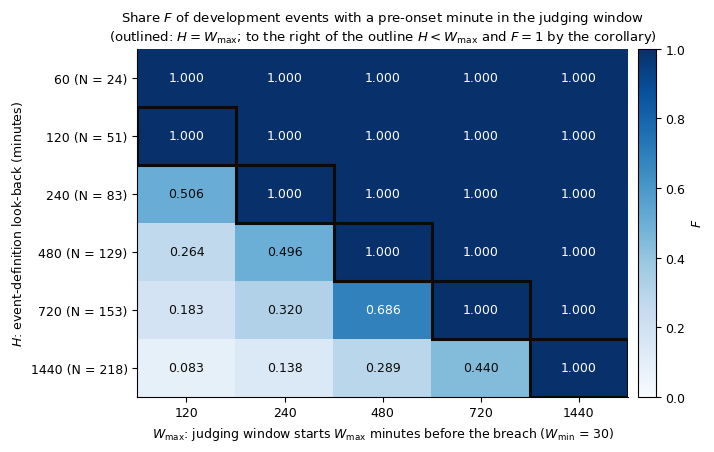

In [11]:
t_ = time.time()
CATF = {H: (CAT[H] if H in CAT else catalog_H(H)) for H in FEAS_H}
VCUM = np.r_[0, np.cumsum(VALID)]
rows = []
for H in FEAS_H:
    ev = events_between(CATF[H], EVAL_START, EVAL_END).reset_index(drop=True)
    br = ev.breach_utc.astype('int64').to_numpy(); on = ev.onset_1pct_utc.astype('int64').to_numpy(); gap = ev.onset_to_breach_minutes.to_numpy(np.int64)
    guard('gap_column', np.array_equal(gap, (br - on) // NS), f'H={H}: onset_to_breach_minutes differs from breach - onset')
    guard('corollary_gap', len(gap) == 0 or gap.max() <= H - 1, f'H={H}: an onset-to-breach gap exceeds H - 1 ({gap.max()})')
    for W in FEAS_W:
        L, pv, iv = window_counts(br, on, W, W_MIN, VCUM, T[0])
        Ld = np.clip(W - gap, 0, W - W_MIN + 1)                                    # notebook-32 closed form
        guard('L_formula', np.array_equal(L, Ld), f'H={H}, W={W}: L_e by counting differs from the closed form')
        n = len(ev); Fv = float((L > 0).mean()) if n else np.nan
        rows.append(dict(H=H, W_max=W, W_min=W_MIN, N=n, F=Fv, impossible_share=1 - Fv if n else np.nan, events_possible=int((L > 0).sum()),
                         pi_valid_minutes=float(iv.sum() / (pv.sum() + iv.sum())) if n else np.nan,
                         pi_all_minutes=1 - float(L.sum() / ((W - W_MIN + 1) * n)) if n else np.nan,
                         invalid_window_minutes=int(n * (W - W_MIN + 1) - pv.sum() - iv.sum()), median_L=float(np.median(L)) if n else np.nan,
                         median_gap_min=float(np.median(gap)) if n else np.nan, max_gap_min=int(gap.max()) if n else -1, H_le_W=H <= W))
FG = pd.DataFrame(rows)
bad = FG[FG.H_le_W & (FG.F != 1.0)]
guard('corollary_F', len(bad) == 0, f'F < 1 although H <= W_max in cells {bad[["H", "W_max", "F"]].to_dict("records")}')
POS32 = pd.read_csv(M32 / '1_pre_onset_possible_by_window.csv').set_index('H')
for H in [120, 240, 480, 1440]:
    r_ = FG[(FG.H == H) & (FG.W_max == 240)].iloc[0]; p32 = POS32.loc[H]
    ok_ = (int(r_.N) == int(p32.events) and abs(r_.F - (1 - float(p32.impossible_share))) < 1e-12 and abs(r_.pi_all_minutes - float(p32.pi_implied_by_L)) < 1e-12
           and abs(r_.pi_valid_minutes - float(p32.pi_share_in_minutes)) < 1e-9)
    guard('nb32_grid_cells', ok_, f'H={H}, W_max=240: N {int(r_.N)}, F {r_.F:.6f}, pi {r_.pi_valid_minutes:.6f}/{r_.pi_all_minutes:.6f} differ from notebook 32 '
                                  f'({int(p32.events)}, {1 - float(p32.impossible_share):.6f}, {float(p32.pi_share_in_minutes):.6f}/{float(p32.pi_implied_by_L):.6f})')
FG.to_csv(OUT / '5_F_pi_grid.csv', index=False)
print(f'PASS: W_max = 240 cells equal notebook 32; F = 1 in every cell with H <= W_max; max gap <= H - 1 for every H ({time.time() - t_:.0f}s)')
display(FG.pivot(index='H', columns='W_max', values='F').round(3)); display(FG.pivot(index='H', columns='W_max', values='pi_valid_minutes').round(3))

# heatmap of F (H rows, W_max columns); H = W_max cells outlined (cells to their right have H < W_max, F = 1 by the corollary)
from matplotlib.patches import Rectangle
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
Fm = FG.pivot(index='H', columns='W_max', values='F').loc[FEAS_H, FEAS_W].to_numpy(float); Nm = FG.pivot(index='H', columns='W_max', values='N').loc[FEAS_H, FEAS_W].to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 4.6))
im = ax.imshow(Fm, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i, H in enumerate(FEAS_H):
    for j, W in enumerate(FEAS_W):
        ax.text(j, i, f'{Fm[i, j]:.3f}', ha='center', va='center', fontsize=9, color='white' if Fm[i, j] > 0.6 else '#0b0b0b')
        if H == W:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, lw=2.2, ec='#0b0b0b'))
ax.set_xticks(range(len(FEAS_W))); ax.set_xticklabels(FEAS_W); ax.set_yticks(range(len(FEAS_H))); ax.set_yticklabels([f'{H} (N = {int(Nm[i, 0])})' for i, H in enumerate(FEAS_H)])
ax.set_xlabel(r'$W_{\max}$: judging window starts $W_{\max}$ minutes before the breach ($W_{\min}$ = 30)'); ax.set_ylabel(r'$H$: event-definition look-back (minutes)')
ax.set_title(r'Share $F$ of development events with a pre-onset minute in the judging window' + '\n' + r'(outlined: $H = W_{\max}$; to the right of the outline $H < W_{\max}$ and $F = 1$ by the corollary)', fontsize=9.5)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label(r'$F$')
plt.tight_layout(); plt.savefig(OUT / 'fig_F_grid.png', dpi=200, bbox_inches='tight'); plt.savefig(OUT / 'fig_F_grid.pdf', bbox_inches='tight'); plt.show()

## 6. Figure 2 (stored notebook 18 event study, no recomputation)

Because the M0 and M1 medians nearly overlap, I draw them with different line styles, widths and marker positions.

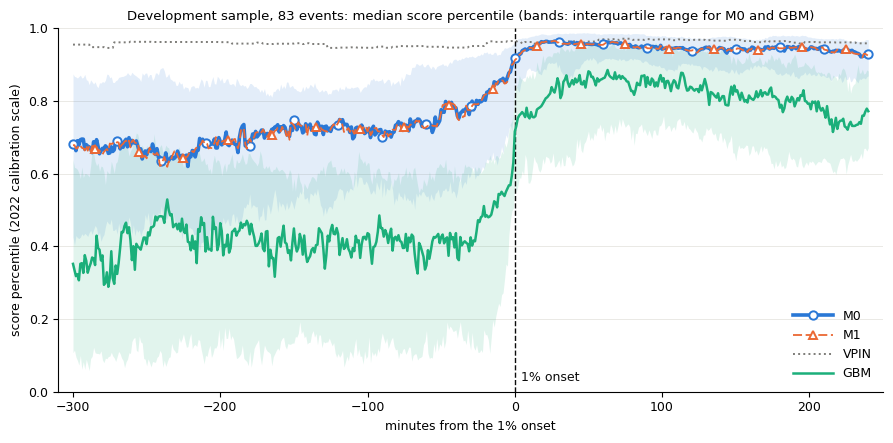

saved /content/drive/MyDrive/btc_lead_cost_results_77months_spot/review_r7_checks_v1/fig2_event_study_r7.png and .pdf


In [12]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
if 'SPOT_BASE' in globals() and 'OUT' in globals():
    ES_CSV = SPOT_BASE / 'standard_protocol_inflation_v1' / '4_event_study.csv'; FIG_DIR = OUT
else:                                                          # standalone: set ES_CSV (notebook-18 4_event_study.csv) and FIG_DIR before running this cell
    ES_CSV = Path(globals().get('ES_CSV', '4_event_study.csv')); FIG_DIR = Path(globals().get('FIG_DIR', '.'))
N_EVENTS_FIG2 = len(EV[240]) if isinstance(globals().get('EV'), dict) and 240 in EV else 83     # 83 development events (main definition)


def draw_fig2(csv_path, fig_dir, n_events=83, x_range=(-300, 240)):
    """Median score percentile by minutes from the 1% onset (notebook-18 event study); IQR bands for M0 and GBM; no prices."""
    es = pd.read_csv(csv_path); es = es[(es.minutes_from_onset >= x_range[0]) & (es.minutes_from_onset <= x_range[1])]
    style = {'M0_VF_logit': dict(label='M0', color='#2a78d6', lw=2.6, ls='-', marker='o', mstart=0, z=4),
             'M1_vol_threshold': dict(label='M1', color='#eb6834', lw=1.3, ls=(0, (5, 2)), marker='^', mstart=15, z=5),
             'M3_GBM_rich': dict(label='GBM', color='#1baf7a', lw=1.8, ls='-', marker=None, mstart=0, z=3),
             'M2_VPIN': dict(label='VPIN', color='#7d7c78', lw=1.4, ls=':', marker=None, mstart=0, z=2),
             'B0_RV24h_baseline': dict(label='B0', color='#52514e', lw=1.4, ls='-.', marker=None, mstart=0, z=2)}
    plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for meth in ['M0_VF_logit', 'M3_GBM_rich']:
        g = es[es.method == meth]
        if len(g):
            ax.fill_between(g.minutes_from_onset, g.q25, g.q75, color=style[meth]['color'], alpha=0.13, lw=0)
    handles = []
    for meth in ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich', 'B0_RV24h_baseline']:
        g = es[es.method == meth].sort_values('minutes_from_onset')
        if not len(g):
            continue
        st = style[meth]; x = g.minutes_from_onset.to_numpy(); y = g.median_pct.to_numpy()
        mk = np.flatnonzero((x - x_range[0] - st['mstart']) % 30 == 0) if st['marker'] else None
        h, = ax.plot(x, y, color=st['color'], lw=st['lw'], ls=st['ls'], marker=st['marker'], markevery=mk, ms=6, mfc='white', mec=st['color'], mew=1.4,
                     label=st['label'], zorder=st['z'])
        handles.append(h)
    ax.axvline(0, color='#0b0b0b', lw=1, ls='--'); ax.text(4, 0.03, '1% onset', fontsize=9, color='#0b0b0b')
    ax.set_xlim(x_range[0] - 10, x_range[1] + 10); ax.set_ylim(0, 1)
    ax.set_xlabel('minutes from the 1% onset'); ax.set_ylabel('score percentile (2022 calibration scale)')
    ax.set_title(f'Development sample, {n_events} events: median score percentile (bands: interquartile range for M0 and GBM)', fontsize=9.5)
    ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
    ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=9, handlelength=3.2)
    plt.tight_layout()
    fig.savefig(Path(fig_dir) / 'fig2_event_study_r7.png', dpi=200); fig.savefig(Path(fig_dir) / 'fig2_event_study_r7.pdf')
    return fig


_fig2 = draw_fig2(ES_CSV, FIG_DIR, N_EVENTS_FIG2); plt.show()
print('saved', Path(FIG_DIR) / 'fig2_event_study_r7.png', 'and .pdf')

## 7. Summary

In [13]:
def _row(df, **kw):
    s_ = df
    for k, v in kw.items():
        s_ = s_[s_[k] == v]
    return s_.iloc[0].to_dict() if len(s_) else None


t3n = T3[T3.buffer == 'none'].set_index('short')
summary = dict(spec_sha256=SPEC_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'],
               mock_bypass_used=bool(any(g['bypassed_in_mock'] for g in GUARDS)), guards=GUARDS,
               section0=dict(events=dict((str(H), len(EV[H])) for H in H_LIST), common_minutes=int(MC.sum()), m0_pre=M0_PRE, m0_post=M0_POST, paired_m0_vs_gbm_H240=PAIR,
                             gbm_minus_m0_point={str(H): Q0[H] for H in (H_REF, H_24)}),
               section1=dict(reading=READING1, verdicts=VERD.to_dict('records'), table3=T3.to_dict('records'), table6=T6.to_dict('records')),
               section2=dict(rows=NB.to_dict('records')),
               section3=dict(rows=EB.to_dict('records')),
               section4=dict(rows=RQ.to_dict('records')),
               section5=dict(rows=FG.to_dict('records')),
               headline=dict(
                   table3_none={s_: dict(auc_standard=float(t3n.loc[s_, 'auc_standard']), auc_pre=float(t3n.loc[s_, 'auc_pre']), S_in=float(t3n.loc[s_, 'S_in']),
                                         auc_pre_within_regime=float(t3n.loc[s_, 'auc_pre_within_regime'])) for s_ in t3n.index},
                   table6_by_buffer={f'H{r.H}|{r.buffer}|{r.quantity}': [float(r.point), float(r.lo), float(r.hi)] for r in T6.itertuples()},
                   budget_nulls={f'{r.short}|{r.endpoint}|{"exact" if "exact" in r.null else "resampler"}': dict(observed=int(r.observed), null_mean=float(r.null_mean), p=float(r.p),
                                                                                                                 p_randomized=None if pd.isna(r.p_randomized) else float(r.p_randomized)) for r in NB.itertuples()},
                   event_bootstrap={f'H{r.H}|{r.variant[0]}|{r.quantity}': [float(r.point), float(r.lo), float(r.hi), bool(r.excludes_zero)] for r in EB.itertuples()},
                   regime_quantiles={f'{r.short}|q{r.strata}': [float(r.auc_pre_within_regime), float(r.auc_pre_within_regime_lo), float(r.auc_pre_within_regime_hi)] for r in RQ.itertuples()},
                   F_grid={f'H{r.H}|W{r.W_max}': dict(N=int(r.N), F=float(r.F), pi=float(r.pi_valid_minutes)) for r in FG.itertuples()}),
               outputs=sorted(p.name for p in OUT.iterdir() if p.is_file()))
(OUT / 'R7_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (bool(o) if isinstance(o, np.bool_) else str(o))))
print(f'guards: {sum(g["passed"] for g in GUARDS)} passed, {sum(not g["passed"] for g in GUARDS)} failed'
      + (f' (bypassed in the mock: {sorted({g["guard"] for g in GUARDS if g["bypassed_in_mock"]})})' if summary['mock_bypass_used'] else ''))
print('Section 1 reading:', READING1)
print('Done. Outputs in', OUT)

guards: 110 passed, 0 failed
Section 1 reading: reading changes
Done. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/review_r7_checks_v1


## 8. Budget × cooldown grid: M0 vs GBM with recalibration for each monthly cap m and cooldown c (H = 240)

For each cell (m, c) I recalibrate the thresholds of the four systems on 2022 by the notebook 16 rule, with a copy of the shared `calibrate_calendar` that passes the cooldown to the scheduler (the frozen function fixes it at 240 minutes). I then issue development-period alerts with the frozen `emit_calendar` (notebook 05; monthly m, yearly 12m, cooldown c) and compare paired events with the notebook 29 code.
The (20, 240) cell is the frozen design, and I add the section-8 results and reading to `R7_SUMMARY.json`.

In [14]:
def calibrate_calendar_cd(t_cal, s_cal, grid=None, B_=240, cap_=20, cooldown_=240):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest).
    Shared calibrate_calendar, changed only to pass the cooldown to the scheduler (the frozen function always uses 240 minutes)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_, cooldown_min=cooldown_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


t_ = time.time(); ev = EV[H_REF]; g_rows = []; p_rows = []; A8 = {}
_okm = EVP & np.isfinite(S0_FULL)
guard('s8_m0_score', np.array_equal(np.isfinite(SC8['M0_VF_logit']) & EVP, _okm) and np.abs(SC8['M0_VF_logit'][_okm] - S0_FULL[_okm]).max() <= 1e-12,
      'section-8 M0 score differs from the notebook-32 M0 score on the development period by more than 1e-12')
_yr, _mo = cal_fields(T[EVP]); MONTHS_PER_YEAR = pd.Series(_mo).groupby(_yr).nunique()        # development months per calendar year (for the largest possible alert count)
for cap in GRID_CAPS:
    for cd in GRID_COOLDOWNS:
        B8 = 12 * cap; flags = {}
        for mname in ALERT_METHODS:
            s8 = SC8[mname]; okc = CAL22 & np.isfinite(s8); oke = EVP & np.isfinite(s8)
            th, ncal, cdf = calibrate_calendar_cd(T[okc], s8[okc], B_=B8, cap_=cap, cooldown_=cd)
            a = emit_calendar(T[oke], s8[oke] >= th, B=B8, cap=cap, cooldown_min=cd)                       # frozen notebook 05 scheduler
            guard('s8_fast_scheduler', np.array_equal(a, emit_calendar_fast(T[oke], s8[oke] >= th, B=B8, cap=cap, cooldown_min=cd)), f'({cap}, {cd}) {mname}: emit_calendar and emit_calendar_fast differ')
            if (cap, cd) == (20, 240):
                th0, n0, df0 = calibrate_calendar(T[okc], s8[okc])
                guard('s8_calibration_copy', th0 == th and n0 == ncal and df0.equals(cdf), f'{mname}: calibrate_calendar_cd(20, 240, 240) differs from the shared calibrate_calendar')
                cfg_ = FROZEN16['configs'][f'{mname}|{DNAME}']
                guard('s8_frozen_threshold', abs(th - float(cfg_['threshold_2022'])) <= 1e-12 and ncal == int(cfg_['cal_alerts_2022']),
                      f'{mname}: (20, 240) threshold {th!r} / 2022 alerts {ncal} differ from notebook 16 ({cfg_["threshold_2022"]!r} / {cfg_["cal_alerts_2022"]})')
                guard('s8_frozen_alerts', np.array_equal(a, ALERTS[mname]) and len(a) == int(cfg_['dev_alerts']), f'{mname}: (20, 240) development alerts differ from the notebook-16 alarm file')
            A8[(cap, cd, mname)] = a
            mm = match_events(ev, a); hit = dict(zip(mm.event_id.astype(int), mm.pre1pct.astype(bool)))
            flags[mname] = dict(pre=np.array([bool(hit.get(int(e), False)) for e in ev.event_id]), any=np.array([int(e) in hit for e in ev.event_id]))
            n_pre = int(flags[mname]['pre'].sum()); n_any = int(flags[mname]['any'].sum())
            g_rows.append(dict(monthly_cap=cap, annual_cap=B8, cooldown_min=cd, system=mname, short=SHORT[mname], threshold_2022=th, alerts_2022=ncal,
                               raw_candidates_2022=int((s8[okc] >= th).sum()), share_2022_minutes_eligible=float((s8[okc] >= th).mean()),
                               alerts=len(a), max_alerts=int(sum(min(cap * k, B8) for k in MONTHS_PER_YEAR)),
                               events=len(ev), caught=n_any, pre=n_pre, in_progress=n_any - n_pre,
                               pre_per_100_alerts=100 * n_pre / len(a) if len(a) else np.nan, in_per_100_alerts=100 * (n_any - n_pre) / len(a) if len(a) else np.nan))
        for endpoint in ['pre', 'any']:
            for a_, b_ in GRID_PAIRS:
                fa, fb = flags[a_][endpoint], flags[b_][endpoint]; n10, n01 = int((fa & ~fb).sum()), int((~fa & fb).sum())
                p = binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
                p_rows.append(dict(monthly_cap=cap, annual_cap=B8, cooldown_min=cd, endpoint=endpoint, pair=f'{a_} vs {b_}', pair_short=f'{SHORT[a_]} vs {SHORT[b_]}', events=len(ev),
                                   a_caught=int(fa.sum()), b_caught=int(fb.sum()), both=int((fa & fb).sum()), a_only=n10, b_only=n01, p_mcnemar=p))
        print(f'cell (m={cap:2d}, c={cd:3d}): ' + ', '.join(f'{r["short"]} {r["alerts"]} alerts / {r["pre"]} pre' for r in g_rows[-len(ALERT_METHODS):]) + f' ({time.time() - t_:.0f}s)', flush=True)
G8 = pd.DataFrame(g_rows); P8 = pd.DataFrame(p_rows)
# guards on the frozen cell against the stored notebook-16 and notebook-29 tables
ref = G8[(G8.monthly_cap == 20) & (G8.cooldown_min == 240)].set_index('system')
for mname in ALERT_METHODS:
    r16 = R16[(R16.method == mname) & (R16.definition == DNAME)].iloc[0]
    guard('s8_frozen_counts', (int(ref.loc[mname, 'pre']), int(ref.loc[mname, 'in_progress'])) == (int(r16.pre), int(r16.post)),
          f'{mname}: (20, 240) pre/in-progress {int(ref.loc[mname, "pre"])}/{int(ref.loc[mname, "in_progress"])} differ from notebook 16 ({int(r16.pre)}/{int(r16.post)})')
rp = P8[(P8.monthly_cap == 20) & (P8.cooldown_min == 240) & (P8.endpoint == 'pre') & (P8.pair == 'M0_VF_logit vs M3_GBM_rich')].iloc[0]
guard('s8_frozen_pairs', all(int(rp[k]) == int(r29[k]) for k in ['events', 'a_caught', 'b_caught', 'both', 'a_only', 'b_only']), 'M0 vs GBM (20, 240) pairs differ from notebook 29')
# the published real-data values of the frozen design (the stored tables above hold the same numbers on the real data)
PUB8 = dict(alerts=(800, 768), pre=(22, 20, 9, 7), pairs=(5, 17, 2))
got8 = dict(alerts=(int(ref.loc['M0_VF_logit', 'alerts']), int(ref.loc['M3_GBM_rich', 'alerts'])), pre=tuple(int(ref.loc[m_, 'pre']) for m_ in ALERT_METHODS),
            pairs=(int(rp.both), int(rp.a_only), int(rp.b_only)))
guard('s8_published_counts', got8 == PUB8, f'(20, 240) cell {got8} differs from the published frozen design {PUB8}')
print('PASS: cell (20, 240) reproduces the frozen thresholds, 2022 alert counts, development alerts, pre-onset counts and M0-vs-GBM pairs')
G8.to_csv(OUT / '8_budget_cooldown_grid.csv', index=False); P8.to_csv(OUT / '8b_paired_by_cell.csv', index=False)
display(G8.pivot_table(index=['monthly_cap', 'cooldown_min'], columns='short', values=['alerts', 'pre', 'pre_per_100_alerts'], sort=False).round(2))
display(P8[P8.endpoint == 'pre'].pivot_table(index=['monthly_cap', 'cooldown_min'], columns='pair_short', values=['both', 'a_only', 'b_only', 'p_mcnemar'], sort=False).round(4))

# ---- pre-specified reading
W8 = G8.pivot_table(index=['monthly_cap', 'cooldown_min'], columns='system', values=['pre', 'pre_per_100_alerts'])
fail_n = [f'(m={i[0]}, c={i[1]}): M0 {int(r[("pre", "M0_VF_logit")])} vs GBM {int(r[("pre", "M3_GBM_rich")])}' for i, r in W8.iterrows() if not r[('pre', 'M0_VF_logit')] > r[('pre', 'M3_GBM_rich')]]
fail_r = [f'(m={i[0]}, c={i[1]}): M0 {r[("pre_per_100_alerts", "M0_VF_logit")]:.2f} vs GBM {r[("pre_per_100_alerts", "M3_GBM_rich")]:.2f} per 100 alerts' for i, r in W8.iterrows()
          if not r[('pre_per_100_alerts', 'M0_VF_logit')] > r[('pre_per_100_alerts', 'M3_GBM_rich')]]
READING8 = dict(direction='direction holds' if not fail_n else 'direction fails', failing_cells=fail_n,
                rate_per_100_alerts='M0 ahead in every cell' if not fail_r else 'M0 not ahead in every cell', failing_cells_rate=fail_r,
                mcnemar_note='exact McNemar p-values per cell are descriptive; no multiplicity claim')
print('Section 8 pre-specified reading:', READING8['direction'], ('' if not fail_n else '; failing cells: ' + '; '.join(fail_n)))
print('Per 100 alerts:', READING8['rate_per_100_alerts'], ('' if not fail_r else '; ' + '; '.join(fail_r)))

# ---- add section 8 to R7_SUMMARY.json
_sj = OUT / 'R7_SUMMARY.json'
summary = json.loads(_sj.read_text()) if _sj.exists() else dict(spec_sha256=SPEC_SHA, status=SPEC['status'], headline={})      # section 7 writes it first
summary.setdefault('headline', {})
summary.update(guards=GUARDS, mock_bypass_used=bool(any(g['bypassed_in_mock'] for g in GUARDS)),
               section8=dict(reading=READING8, grid=G8.to_dict('records'), paired=P8.to_dict('records')),
               outputs=sorted(p.name for p in OUT.iterdir() if p.is_file()))
summary['headline']['budget_cooldown_grid'] = {f'm{r.monthly_cap}|c{r.cooldown_min}|{r.short}': dict(alerts=int(r.alerts), pre=int(r.pre), in_progress=int(r.in_progress),
                                                                                                       pre_per_100=float(r.pre_per_100_alerts), threshold_2022=float(r.threshold_2022)) for r in G8.itertuples()}
summary['headline']['budget_cooldown_pairs_pre'] = {f'm{r.monthly_cap}|c{r.cooldown_min}|{r.pair_short}': dict(both=int(r.both), a_only=int(r.a_only), b_only=int(r.b_only), p_mcnemar=float(r.p_mcnemar))
                                                    for r in P8[P8.endpoint == 'pre'].itertuples()}
summary['headline']['section8_reading'] = READING8['direction']
(OUT / 'R7_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (bool(o) if isinstance(o, np.bool_) else str(o))))
print(f'R7_SUMMARY.json updated with section 8; guards: {sum(g["passed"] for g in GUARDS)} passed, {sum(not g["passed"] for g in GUARDS)} failed'
      + (f' (bypassed in the mock: {sorted({g["guard"] for g in GUARDS if g["bypassed_in_mock"]})})' if summary['mock_bypass_used'] else '') + f' ({time.time() - t_:.0f}s)')

cell (m=10, c= 60): M0 400 alerts / 9 pre, M1 400 alerts / 8 pre, VPIN 400 alerts / 1 pre, GBM 376 alerts / 2 pre (17s)
cell (m=10, c=120): M0 400 alerts / 10 pre, M1 400 alerts / 8 pre, VPIN 400 alerts / 1 pre, GBM 377 alerts / 5 pre (31s)
cell (m=10, c=240): M0 400 alerts / 11 pre, M1 400 alerts / 9 pre, VPIN 400 alerts / 4 pre, GBM 365 alerts / 4 pre (45s)
cell (m=20, c= 60): M0 800 alerts / 11 pre, M1 800 alerts / 11 pre, VPIN 799 alerts / 1 pre, GBM 714 alerts / 6 pre (60s)
cell (m=20, c=120): M0 800 alerts / 16 pre, M1 800 alerts / 16 pre, VPIN 797 alerts / 5 pre, GBM 710 alerts / 7 pre (75s)
cell (m=20, c=240): M0 800 alerts / 22 pre, M1 800 alerts / 20 pre, VPIN 800 alerts / 9 pre, GBM 768 alerts / 7 pre (95s)
cell (m=40, c= 60): M0 1600 alerts / 14 pre, M1 1600 alerts / 15 pre, VPIN 1591 alerts / 5 pre, GBM 1402 alerts / 12 pre (112s)
cell (m=40, c=120): M0 1600 alerts / 19 pre, M1 1600 alerts / 18 pre, VPIN 1594 alerts / 11 pre, GBM 1574 alerts / 22 pre (130s)
cell (m=40, c=2

alerts                           pre              \
short                         M0      M1    VPIN     GBM    M0    M1  VPIN   
monthly_cap cooldown_min                                                     
10          60             400.0   400.0   400.0   376.0   9.0   8.0   1.0   
            120            400.0   400.0   400.0   377.0  10.0   8.0   1.0   
            240            400.0   400.0   400.0   365.0  11.0   9.0   4.0   
20          60             800.0   800.0   799.0   714.0  11.0  11.0   1.0   
            120            800.0   800.0   797.0   710.0  16.0  16.0   5.0   
            240            800.0   800.0   800.0   768.0  22.0  20.0   9.0   
40          60            1600.0  1600.0  1591.0  1402.0  14.0  15.0   5.0   
            120           1600.0  1600.0  1594.0  1574.0  19.0  18.0  11.0   
            240           1600.0  1600.0  1600.0  1581.0  24.0  29.0  14.0   

                               pre_per_100_alerts                    
short                      GBM                 M0    M1  VPIN   GBM  
monthly_cap cooldown_min                                             
10          60             2.0               2.25  2.00  0.25  0.53  
            120            5.0               2.50  2.00  0.25  1.33  
            240            4.0               2.75  2.25  1.00  1.10  
20          60             6.0               1.38  1.38  0.13  0.84  
            120            7.0               2.00  2.00  0.63  0.99  
            240            7.0               2.75  2.50  1.12  0.91  
40          60            12.0               0.88  0.94  0.31  0.86  
            120           22.0               1.19  1.12  0.69  1.40  
            240           19.0               1.50  1.81  0.88  1.20

both             a_only             b_only  \
pair_short               M0 vs GBM M0 vs M1 M0 vs GBM M0 vs M1 M0 vs GBM   
monthly_cap cooldown_min                                                   
10          60                 1.0      8.0       8.0      1.0       1.0   
            120                1.0      8.0       9.0      2.0       4.0   
            240                1.0      9.0      10.0      2.0       3.0   
20          60                 2.0     11.0       9.0      0.0       4.0   
            120                2.0     15.0      14.0      1.0       5.0   
            240                5.0     19.0      17.0      3.0       2.0   
40          60                 3.0     14.0      11.0      0.0       9.0   
            120               16.0     16.0       3.0      3.0       6.0   
            240               12.0     24.0      12.0      0.0       7.0   

                                  p_mcnemar           
pair_short               M0 vs M1 M0 vs GBM M0 vs M1  
monthly_cap cooldown_min                              
10          60                0.0    0.0391   1.0000  
            120               0.0    0.2668   0.5000  
            240               0.0    0.0923   0.5000  
20          60                0.0    0.2668   1.0000  
            120               1.0    0.0636   1.0000  
            240               1.0    0.0007   0.6250  
40          60                1.0    0.8238   1.0000  
            120               2.0    0.5078   1.0000  
            240               5.0    0.3593   0.0625

Section 8 pre-specified reading: direction fails ; failing cells: (m=40, c=120): M0 19 vs GBM 22
Per 100 alerts: M0 not ahead in every cell ; (m=40, c=120): M0 1.19 vs GBM 1.40 per 100 alerts
R7_SUMMARY.json updated with section 8; guards: 165 passed, 0 failed (150s)


## Interpretation
- Section 1: rows X = 0, 240 and 1440 remove the 29 minutes before each breach and the X minutes after it from the negatives; the pre-specified reading concerns the sign and relation to zero of the Table 6 intervals, the M0 within-regime AUC and whether B0 leads on pre-onset AUC, not the AUC level, and I print it as `reading unchanged / reading changes`, with failed items in `failed_items`.
- Section 2: the exact null is uniform over placements that keep the per-cell alert counts and the cooldown exactly, and the resampler approximates it, so their means can differ (M0: 6.70 vs 6.27); p-values describe the development sample.
- Section 3: the event bootstrap draws the minutes of one event together; at 24 hours pre-onset minutes occur in only a few events (30 in the real data, `feasible_events`), and `share_draws_finite` < 1 means that some draws contained no such event.
- Section 5: F = 1 when H ≤ W_max by the corollary; when H > W_max some events have their onset before the judging window, so no system can warn before onset, and π shows how large the in-progress share of the standard AUC becomes by definition alone.
- Section 8: I recalibrate thresholds on 2022 in each cell, so development-period alert counts can differ by system, and I report catches per 100 alerts alongside the counts; `direction holds / direction fails` is the pre-specified reading.
- All results are exploratory descriptions of a development period that I have examined many times.